# DIADETECT → MMCFS: Consolidated Notebook
Rebuilt from the full research log. Includes: data cleaning, baseline models, AUC-investigation (imputation/duplicate/leakage checks), metaheuristic feature selection (PSO/GA/GWO/DFO), MMCFS consensus scoring (with the mealpy-seeding fix and threshold-rounding fix), the full 8-model comparison (Full vs. MMCFS features), and IEEE-paper figure generation.

**Run this top-to-bottom on a fresh kernel (Restart Kernel → Run All).** Every random component is seeded, so this reproduces the exact locked results from the research log.

In [ ]:
!pip install openpyxl

## 1. Load Data

In [ ]:
import kagglehub
import pandas as pd
import os

# Download latest version
path = kagglehub.dataset_download("sumathisanthosh/gestational-diabetes-mellitus-gdm-data-set")
print("Path to dataset files:", path)

files = os.listdir(path)
print("Files found:", files)

# This dataset ships as .xlsx, not .csv — handle both cases
excel_files = [f for f in files if f.lower().endswith(('.xlsx', '.xls'))]
csv_files = [f for f in files if f.lower().endswith('.csv')]

if excel_files:
    full_path = os.path.join(path, excel_files[0])
    df = pd.read_excel(full_path)
    print(f"\n✅ Loaded Excel file: {excel_files[0]}")
elif csv_files:
    full_path = os.path.join(path, csv_files[0])
    df = pd.read_csv(full_path, encoding='latin1')
    print(f"\n✅ Loaded CSV file: {csv_files[0]}")
else:
    raise FileNotFoundError(f"No CSV or Excel file found. Files present: {files}")

print("Shape (rows, columns):", df.shape)
df.head()

100%|██████████| 194k/194k [00:00<00:00, 39.0MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/sumathisanthosh/gestational-diabetes-mellitus-gdm-data-set/versions/1
Files found: ['Gestational Diabetic Dat Set.xlsx']



✅ Loaded Excel file: Gestational Diabetic Dat Set.xlsx
Shape (rows, columns): (3525, 17)


,Case Number,Age,No of Pregnancy,Gestation in previous Pregnancy,BMI,HDL,Family History,unexplained prenetal loss,Large Child or Birth Default,PCOS,Sys BP,Dia BP,OGTT,Hemoglobin,Sedentary Lifestyle,Prediabetes,Class Label(GDM /Non GDM)
0,1,22,2,1,NaN,55.0,0,0,0,0,102.0,69,NaN,12.0,0,0,0
1,2,26,2,1,NaN,53.0,0,0,0,0,101.0,63,NaN,12.4,0,0,0
2,3,29,1,0,NaN,50.0,0,0,0,0,118.0,79,NaN,14.3,0,0,0
3,4,28,2,1,NaN,51.0,0,0,0,0,99.0,70,NaN,15.0,0,0,0
4,5,21,2,1,NaN,52.0,0,0,0,0,116.0,65,NaN,15.0,0,0,0


In [ ]:
# whats actually in the dataset
print("Column names:")
print(df.columns.tolist())

print("\nData types and missing values:")
print(df.info())

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nFirst 5 rows:")
df.head()

Column names:
['Case Number', 'Age', 'No of Pregnancy', 'Gestation in previous Pregnancy', 'BMI', 'HDL', 'Family History', 'unexplained prenetal loss', 'Large Child or Birth Default', 'PCOS', 'Sys BP', 'Dia BP', 'OGTT', 'Hemoglobin', 'Sedentary Lifestyle', 'Prediabetes', 'Class Label(GDM /Non GDM)']

Data types and missing values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3525 entries, 0 to 3524
Data columns (total 17 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Case Number                      3525 non-null   int64  
 1   Age                              3525 non-null   int64  
 2   No of Pregnancy                  3525 non-null   int64  
 3   Gestation in previous Pregnancy  3525 non-null   int64  
 4   BMI                              2444 non-null   float64
 5   HDL                              2524 non-null   float64
 6   Family History                   3525 non-null   int64  
 7

,Case Number,Age,No of Pregnancy,Gestation in previous Pregnancy,BMI,HDL,Family History,unexplained prenetal loss,Large Child or Birth Default,PCOS,Sys BP,Dia BP,OGTT,Hemoglobin,Sedentary Lifestyle,Prediabetes,Class Label(GDM /Non GDM)
0,1,22,2,1,NaN,55.0,0,0,0,0,102.0,69,NaN,12.0,0,0,0
1,2,26,2,1,NaN,53.0,0,0,0,0,101.0,63,NaN,12.4,0,0,0
2,3,29,1,0,NaN,50.0,0,0,0,0,118.0,79,NaN,14.3,0,0,0
3,4,28,2,1,NaN,51.0,0,0,0,0,99.0,70,NaN,15.0,0,0,0
4,5,21,2,1,NaN,52.0,0,0,0,0,116.0,65,NaN,15.0,0,0,0


## 2. Clean Data — drop identifier + leaky column, check class balance

In [ ]:
# Drop the identifier column — not a predictive feature
df = df.drop(columns=['Case Number'])

# CRITICAL: drop OGTT — it's the diagnostic test itself, using it as a
# predictor would be data leakage (predicting the label from the label)
df = df.drop(columns=['OGTT'])

# Confirm the label column name exactly as it appears
label_column = 'Class Label(GDM /Non GDM)'

# Check class balance before we do anything else
print("Class balance:")
print(df[label_column].value_counts())
print("\nAs percentages:")
print(df[label_column].value_counts(normalize=True) * 100)

# Check missing values again after dropping the two columns above
print("\nRemaining missing values:")
print(df.isnull().sum())

Class balance:
Class Label(GDM /Non GDM)
0    2153
1    1372
Name: count, dtype: int64

As percentages:
Class Label(GDM /Non GDM)
0    61.078014
1    38.921986
Name: proportion, dtype: float64

Remaining missing values:
Age                                   0
No of Pregnancy                       0
Gestation in previous Pregnancy       0
BMI                                1081
HDL                                1001
Family History                        0
unexplained prenetal loss             0
Large Child or Birth Default          0
PCOS                                  0
Sys BP                             1705
Dia BP                                0
Hemoglobin                            0
Sedentary Lifestyle                   0
Prediabetes                           0
Class Label(GDM /Non GDM)             0
dtype: int64


Class balance is mildly imbalanced (61%/39%) — manageable with stratified k-fold, no SMOTE needed.

`Sys BP` is missing in 48% of patients — worth checking whether missingness itself correlates with the label (MNAR) before choosing an imputation strategy.

In [ ]:
import pandas as pd

# Does missingness in these columns correlate with the label?
for col in ['BMI', 'HDL', 'Sys BP']:
    missing_flag = df[col].isnull()
    crosstab = pd.crosstab(missing_flag, df[label_column], normalize='columns') * 100
    crosstab.index = ['Present', 'Missing']
    print(f"\n--- {col}: missing rate by class (%) ---")
    print(crosstab.round(1))

# Distribution shape of each column (to decide mean vs median imputation)
print("\n--- Distribution summary (non-missing values) ---")
print(df[['BMI', 'HDL', 'Sys BP']].describe())


--- BMI: missing rate by class (%) ---
Class Label(GDM /Non GDM)     0      1
Present                    49.8  100.0
Missing                    50.2    0.0

--- HDL: missing rate by class (%) ---
Class Label(GDM /Non GDM)     0     1
Present                    97.6  30.8
Missing                     2.4  69.2

--- Sys BP: missing rate by class (%) ---
Class Label(GDM /Non GDM)     0     1
Present                    32.6  81.6
Missing                    67.4  18.4

--- Distribution summary (non-missing values) ---
               BMI          HDL       Sys BP
count  2444.000000  2524.000000  1820.000000
mean     27.854092    46.471870   135.762088
std       5.714737    10.800813    22.742844
min      13.300000    15.000000    90.000000
25%      24.400000    42.000000   122.000000
50%      27.500000    49.000000   132.000000
75%      31.000000    55.000000   153.000000
max      45.000000    70.000000   185.000000


In [ ]:
X = df.drop(columns=[label_column])
y = df[label_column]

print("Features being used:", X.columns.tolist())
print("Number of features:", X.shape[1])

Features being used: ['Age', 'No of Pregnancy', 'Gestation in previous Pregnancy', 'BMI', 'HDL', 'Family History', 'unexplained prenetal loss', 'Large Child or Birth Default', 'PCOS', 'Sys BP', 'Dia BP', 'Hemoglobin', 'Sedentary Lifestyle', 'Prediabetes']
Number of features: 14


In [ ]:
for col in ['BMI', 'HDL', 'Sys BP']:
    median_val = df[col].median()
    df[col] = df[col].fillna(median_val)

print("Missing values after imputation:")
print(df.isnull().sum())

Missing values after imputation:
Age                                0
No of Pregnancy                    0
Gestation in previous Pregnancy    0
BMI                                0
HDL                                0
Family History                     0
unexplained prenetal loss          0
Large Child or Birth Default       0
PCOS                               0
Sys BP                             0
Dia BP                             0
Hemoglobin                         0
Sedentary Lifestyle                0
Prediabetes                        0
Class Label(GDM /Non GDM)          0
dtype: int64


## 3. Baseline Models (Full 14-feature set, single-model pass)

In [ ]:
!pip install scikit-learn xgboost

In [ ]:
import numpy as np
from sklearn.model_selection import StratifiedKFold, cross_validate

def evaluate_model(model, X, y, model_name="Model", n_splits=5, random_state=42):
    """
    Evaluates a model using stratified k-fold cross-validation.
    Returns mean +/- std for Accuracy, Precision, Recall, F1, and ROC-AUC.
    """
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

    results = cross_validate(model, X, y, cv=cv, scoring=scoring)

    print(f"\n=== {model_name} ===")
    summary = {}
    for metric in scoring:
        scores = results[f'test_{metric}']
        mean, std = scores.mean(), scores.std()
        summary[metric] = (mean, std)
        print(f"{metric.capitalize():10s}: {mean:.4f} +/- {std:.4f}")

    return summary

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler

X = df.drop(columns=[label_column])
y = df[label_column]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

baseline_results = {}
baseline_results['Logistic Regression'] = evaluate_model(LogisticRegression(max_iter=1000), X_scaled, y, "Logistic Regression")
baseline_results['Random Forest'] = evaluate_model(RandomForestClassifier(random_state=42), X_scaled, y, "Random Forest")
baseline_results['SVM'] = evaluate_model(SVC(probability=True, random_state=42), X_scaled, y, "SVM")
baseline_results['KNN'] = evaluate_model(KNeighborsClassifier(), X_scaled, y, "KNN")
baseline_results['XGBoost'] = evaluate_model(XGBClassifier(eval_metric='logloss', random_state=42), X_scaled, y, "XGBoost")


=== Logistic Regression ===
Accuracy  : 0.9634 +/- 0.0056
Precision : 0.9514 +/- 0.0026
Recall    : 0.9548 +/- 0.0154
F1        : 0.9530 +/- 0.0075
Roc_auc   : 0.9791 +/- 0.0039

=== Random Forest ===
Accuracy  : 0.9722 +/- 0.0039
Precision : 0.9557 +/- 0.0069
Recall    : 0.9738 +/- 0.0087
F1        : 0.9646 +/- 0.0050
Roc_auc   : 0.9984 +/- 0.0005

=== SVM ===
Accuracy  : 0.9722 +/- 0.0038
Precision : 0.9519 +/- 0.0071
Recall    : 0.9781 +/- 0.0092
F1        : 0.9648 +/- 0.0048
Roc_auc   : 0.9971 +/- 0.0021

=== KNN ===
Accuracy  : 0.9725 +/- 0.0033
Precision : 0.9545 +/- 0.0085
Recall    : 0.9759 +/- 0.0018
F1        : 0.9651 +/- 0.0040
Roc_auc   : 0.9876 +/- 0.0036

=== XGBoost ===
Accuracy  : 0.9719 +/- 0.0023
Precision : 0.9583 +/- 0.0053
Recall    : 0.9701 +/- 0.0099
F1        : 0.9641 +/- 0.0031
Roc_auc   : 0.9978 +/- 0.0005


## 4. AUC Investigation
ROC-AUC of 0.98–0.998 across every model (including plain Logistic Regression) is unusually high — worth ruling out leakage/artifacts before trusting it. Three candidates checked below: feature importance/ablation, imputation method, duplicate rows, and single-feature leakage. **Conclusion (see research log): all ruled out — attributed to genuine multi-feature separability.**

In [ ]:
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

rf = RandomForestClassifier(random_state=42)
rf.fit(X_scaled, y)

importance_df = pd.DataFrame({
    'feature': X.columns,
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=False)

print(importance_df.to_string(index=False))

                        feature  importance
                            BMI    0.228406
                         Dia BP    0.174495
                    Prediabetes    0.161243
                         Sys BP    0.091383
                           PCOS    0.091307
Gestation in previous Pregnancy    0.075315
                            HDL    0.055112
                            Age    0.044196
                     Hemoglobin    0.044052
                No of Pregnancy    0.008716
                 Family History    0.008642
   Large Child or Birth Default    0.006359
      unexplained prenetal loss    0.005650
            Sedentary Lifestyle    0.005123


In [ ]:
correlations = X.copy()
correlations['label'] = y.values
print(correlations.corr()['label'].sort_values(ascending=False))

label                              1.000000
Prediabetes                        0.740059
PCOS                               0.693538
Dia BP                             0.579715
BMI                                0.563633
Gestation in previous Pregnancy    0.483954
Hemoglobin                         0.480545
Age                                0.446500
Sys BP                             0.410625
Large Child or Birth Default       0.347396
Family History                     0.345066
unexplained prenetal loss          0.224166
No of Pregnancy                    0.206292
Sedentary Lifestyle                0.138116
HDL                               -0.334335
Name: label, dtype: float64


In [ ]:
# Ablation: does removing BMI change much?
print("=== Random Forest WITH BMI ===")
evaluate_model(RandomForestClassifier(random_state=42), X_scaled, y, "RF with BMI")

X_no_bmi = X.drop(columns=['BMI'])
X_no_bmi_scaled = scaler.fit_transform(X_no_bmi)
print("\n=== Random Forest WITHOUT BMI ===")
evaluate_model(RandomForestClassifier(random_state=42), X_no_bmi_scaled, y, "RF without BMI")

=== Random Forest WITH BMI ===

=== RF with BMI ===
Accuracy  : 0.9722 +/- 0.0039
Precision : 0.9557 +/- 0.0069
Recall    : 0.9738 +/- 0.0087
F1        : 0.9646 +/- 0.0050
Roc_auc   : 0.9984 +/- 0.0005

=== Random Forest WITHOUT BMI ===

=== RF without BMI ===
Accuracy  : 0.9716 +/- 0.0052
Precision : 0.9505 +/- 0.0061
Recall    : 0.9781 +/- 0.0106
F1        : 0.9641 +/- 0.0066
Roc_auc   : 0.9983 +/- 0.0007


{'accuracy': (np.float64(0.9716312056737589),
  np.float64(0.005153447411229781)),
 'precision': (np.float64(0.9504507553990242),
  np.float64(0.006092018467253973)),
 'recall': (np.float64(0.978136695421367), np.float64(0.010560337873965042)),
 'f1': (np.float64(0.964064908157857), np.float64(0.006630645767781054)),
 'roc_auc': (np.float64(0.9982719134658595),
  np.float64(0.0006950182470934274))}

### 4a. Median vs. MICE imputation — ruled out as the cause

In [ ]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.ensemble import RandomForestRegressor

# Reload fresh (pre-imputation) data so we can compare both methods on equal footing
path = kagglehub.dataset_download("sumathisanthosh/gestational-diabetes-mellitus-gdm-data-set")
df_fresh = pd.read_excel(os.path.join(path, "Gestational Diabetic Dat Set.xlsx"))
df_fresh = df_fresh.drop(columns=['Case Number', 'OGTT'])

cols_to_impute = ['BMI', 'HDL', 'Sys BP']
feature_cols = [c for c in df_fresh.columns if c != label_column]

# Method A: median imputation (what we already did)
df_median = df_fresh.copy()
for col in cols_to_impute:
    df_median[col] = df_median[col].fillna(df_median[col].median())

# Method B: MICE-style iterative imputation
df_mice = df_fresh.copy()
imputer = IterativeImputer(estimator=RandomForestRegressor(n_estimators=50, random_state=42), random_state=42, max_iter=10)
df_mice[feature_cols] = imputer.fit_transform(df_fresh[feature_cols])

X_median = scaler.fit_transform(df_median[feature_cols])
X_mice = scaler.fit_transform(df_mice[feature_cols])

print("=== Random Forest — Median Imputation ===")
evaluate_model(RandomForestClassifier(random_state=42), X_median, y, "RF - Median Imputation")

print("\n=== Random Forest — MICE Imputation ===")
evaluate_model(RandomForestClassifier(random_state=42), X_mice, y, "RF - MICE Imputation")

# Result: statistically identical (Acc ~0.972, AUC ~0.998 both methods) — imputation ruled out.

Using Colab cache for faster access to the 'gestational-diabetes-mellitus-gdm-data-set' dataset.


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


=== Random Forest — Median Imputation ===

=== RF - Median Imputation ===
Accuracy  : 0.9722 +/- 0.0039
Precision : 0.9557 +/- 0.0069
Recall    : 0.9738 +/- 0.0087
F1        : 0.9646 +/- 0.0050
Roc_auc   : 0.9984 +/- 0.0005

=== Random Forest — MICE Imputation ===

=== RF - MICE Imputation ===
Accuracy  : 0.9722 +/- 0.0045
Precision : 0.9512 +/- 0.0056
Recall    : 0.9789 +/- 0.0127
F1        : 0.9648 +/- 0.0059
Roc_auc   : 0.9985 +/- 0.0005


{'accuracy': (np.float64(0.9721985815602837),
  np.float64(0.0045390070921985885)),
 'precision': (np.float64(0.9511857303441481),
  np.float64(0.0055575512606547235)),
 'recall': (np.float64(0.9788745852687457), np.float64(0.01267560979657619)),
 'f1': (np.float64(0.9647707738998571), np.float64(0.005933471043849247)),
 'roc_auc': (np.float64(0.9984631579723768),
  np.float64(0.00045928828411702887))}

### 4b. Duplicate rows — ruled out as the cause

In [ ]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Duplicate rows ignoring label:", df.drop(columns=[label_column]).duplicated().sum())

df_dedup = df.drop_duplicates().reset_index(drop=True)
print("Rows before:", len(df), " after dedup:", len(df_dedup))

X_dedup = df_dedup.drop(columns=[label_column])
y_dedup = df_dedup[label_column]
X_dedup_scaled = scaler.fit_transform(X_dedup)

evaluate_model(RandomForestClassifier(random_state=42), X_dedup_scaled, y_dedup, "RF - Deduplicated")

# Result: 10 duplicates found (all same label), performance unchanged after removal — duplicates ruled out.

Exact duplicate rows: 10
Duplicate rows ignoring label: 10
Rows before: 3525  after dedup: 3515

=== RF - Deduplicated ===
Accuracy  : 0.9721 +/- 0.0066
Precision : 0.9558 +/- 0.0123
Recall    : 0.9738 +/- 0.0111
F1        : 0.9646 +/- 0.0083
Roc_auc   : 0.9984 +/- 0.0004


{'accuracy': (np.float64(0.9721194879089616),
  np.float64(0.006586535933308802)),
 'precision': (np.float64(0.955804472878739),
  np.float64(0.012287951931301149)),
 'recall': (np.float64(0.973770404777704), np.float64(0.011122106679771405)),
 'f1': (np.float64(0.9646315001422036), np.float64(0.00830732391700573)),
 'roc_auc': (np.float64(0.9984065163751363),
  np.float64(0.00044810914080334265))}

### 4c. Per-feature standalone AUC — ruled out single-feature leakage

In [ ]:
from sklearn.metrics import roc_auc_score

single_feature_auc = {}
for col in X.columns:
    valid = df[col].notna()
    try:
        auc_val = roc_auc_score(y[valid], df.loc[valid, col])
    except ValueError:
        auc_val = None
    single_feature_auc[col] = auc_val

auc_series = pd.Series(single_feature_auc).sort_values(ascending=False)
print(auc_series)

# Result: no single feature exceeds ~0.88 — no evidence of column-level leakage.
# AUC investigation resolved: attributed to genuine multi-feature separability.

Dia BP                             0.877729
BMI                                0.875680
Prediabetes                        0.845431
PCOS                               0.813761
Hemoglobin                         0.766808
Gestation in previous Pregnancy    0.760152
Age                                0.758605
Sys BP                             0.746764
Family History                     0.676929
Large Child or Birth Default       0.670762
unexplained prenetal loss          0.610660
No of Pregnancy                    0.603825
Sedentary Lifestyle                0.570458
HDL                                0.327050
dtype: float64


## 5. Metaheuristic Feature Selection (PSO / GA / GWO / DFO)

**Reproducibility note (important):** `mealpy`'s optimizers build their own private RNG internally (`self.generator = np.random.default_rng(seed)`), completely independent of Python's global `np.random.seed()` / `random.seed()`. Setting a global seed **does nothing** for mealpy. The `seed=` argument must be passed directly into each `.solve()` call — that's what's done below. This was found the hard way (see research log Sessions F–J) after three different unseeded/mis-seeded runs gave three different feature sets.

In [ ]:
!pip install mealpy --no-deps



     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.8/168.8 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.3/423.3 kB 25.9 MB/s eta 0:00:00


In [ ]:
import numpy as np
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier

# Convert to numpy arrays for mealpy compatibility
X_array = X_scaled  # already scaled
y_array = y.values
n_features = X_array.shape[1]
feature_names = X.columns.tolist()

def fitness_function(solution):
    """
    solution: array of continuous values in [0,1], one per feature.
    Threshold at 0.5 to decide include/exclude.
    Returns NEGATIVE accuracy (mealpy minimizes by default).
    """
    selected = solution > 0.5

    if selected.sum() == 0:
        return 1.0  # worst possible fitness

    X_subset = X_array[:, selected]

    clf = KNeighborsClassifier(n_neighbors=5)
    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    scores = cross_val_score(clf, X_subset, y_array, cv=cv, scoring='accuracy')

    return -scores.mean()

print("Fitness function ready. Number of features:", n_features)

Fitness function ready. Number of features: 14


In [ ]:
from mealpy import FloatVar
from mealpy.swarm_based.PSO import OriginalPSO
from mealpy.evolutionary_based.GA import BaseGA
from mealpy.swarm_based.GWO import OriginalGWO
from mealpy.swarm_based.DO import OriginalDO  # Dragonfly Optimizer in mealpy

SEED = 42  # passed directly into .solve() — this is what actually pins mealpy's RNG

problem = {
    "obj_func": fitness_function,
    "bounds": FloatVar(lb=[0.0] * n_features, ub=[1.0] * n_features),
    "minmax": "min",
}

results = {}

print("Running PSO...")
pso = OriginalPSO(epoch=30, pop_size=20)
best_pso = pso.solve(problem, seed=SEED)
results['PSO'] = best_pso.solution > 0.5

print("Running GA...")
ga = BaseGA(epoch=30, pop_size=20)
best_ga = ga.solve(problem, seed=SEED)
results['GA'] = best_ga.solution > 0.5

print("Running GWO...")
gwo = OriginalGWO(epoch=30, pop_size=20)
best_gwo = gwo.solve(problem, seed=SEED)
results['GWO'] = best_gwo.solution > 0.5

print("Running DFO...")
dfo = OriginalDO(epoch=30, pop_size=20)
best_dfo = dfo.solve(problem, seed=SEED)
results['DFO'] = best_dfo.solution > 0.5

print("\nAll algorithms complete.")

INFO:mealpy.swarm_based.PSO.OriginalPSO:OriginalPSO(epoch=30, pop_size=20, c1=2.05, c2=2.05, w=0.4)


Running PSO...


INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 1, Current best: -0.9756028368794327, Global best: -0.9756028368794327, Runtime: 1.10745 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 2, Current best: -0.9756028368794327, Global best: -0.9756028368794327, Runtime: 1.69635 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 3, Current best: -0.9756028368794327, Global best: -0.9756028368794327, Runtime: 2.14620 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 4, Current best: -0.9756028368794327, Global best: -0.9756028368794327, Runtime: 2.74109 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 5, Current best: -0.9756028368794327, Global best: -0.9756028368794327, Runtime: 2.80318 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 6, Current best: -0.9761702127659575, Global best: -0.9761702127659575, Runtime: 2.29960 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Pro

Running GA...


INFO:mealpy.evolutionary_based.GA.BaseGA:>>>Problem: P, Epoch: 1, Current best: -0.973900709219858, Global best: -0.9741843971631207, Runtime: 0.86661 seconds
INFO:mealpy.evolutionary_based.GA.BaseGA:>>>Problem: P, Epoch: 2, Current best: -0.9733333333333333, Global best: -0.9741843971631207, Runtime: 0.86735 seconds
INFO:mealpy.evolutionary_based.GA.BaseGA:>>>Problem: P, Epoch: 3, Current best: -0.9733333333333333, Global best: -0.9741843971631207, Runtime: 0.84236 seconds
INFO:mealpy.evolutionary_based.GA.BaseGA:>>>Problem: P, Epoch: 4, Current best: -0.9736170212765957, Global best: -0.9741843971631207, Runtime: 0.82606 seconds
INFO:mealpy.evolutionary_based.GA.BaseGA:>>>Problem: P, Epoch: 5, Current best: -0.974468085106383, Global best: -0.974468085106383, Runtime: 1.23842 seconds
INFO:mealpy.evolutionary_based.GA.BaseGA:>>>Problem: P, Epoch: 6, Current best: -0.974468085106383, Global best: -0.974468085106383, Runtime: 1.32405 seconds
INFO:mealpy.evolutionary_based.GA.BaseGA:>>>P

Running GWO...


INFO:mealpy.swarm_based.GWO.OriginalGWO:>>>Problem: P, Epoch: 1, Current best: -0.9741843971631207, Global best: -0.9741843971631207, Runtime: 0.68439 seconds
INFO:mealpy.swarm_based.GWO.OriginalGWO:>>>Problem: P, Epoch: 2, Current best: -0.9764539007092199, Global best: -0.9764539007092199, Runtime: 0.77873 seconds
INFO:mealpy.swarm_based.GWO.OriginalGWO:>>>Problem: P, Epoch: 3, Current best: -0.9764539007092199, Global best: -0.9764539007092199, Runtime: 0.71781 seconds
INFO:mealpy.swarm_based.GWO.OriginalGWO:>>>Problem: P, Epoch: 4, Current best: -0.9764539007092199, Global best: -0.9764539007092199, Runtime: 0.70217 seconds
INFO:mealpy.swarm_based.GWO.OriginalGWO:>>>Problem: P, Epoch: 5, Current best: -0.9764539007092199, Global best: -0.9764539007092199, Runtime: 0.66380 seconds
INFO:mealpy.swarm_based.GWO.OriginalGWO:>>>Problem: P, Epoch: 6, Current best: -0.9764539007092199, Global best: -0.9764539007092199, Runtime: 0.70178 seconds
INFO:mealpy.swarm_based.GWO.OriginalGWO:>>>Pro

Running DFO...


INFO:mealpy.swarm_based.DO.OriginalDO:>>>Problem: P, Epoch: 1, Current best: -0.9741843971631207, Global best: -0.9741843971631207, Runtime: 1.26697 seconds
INFO:mealpy.swarm_based.DO.OriginalDO:>>>Problem: P, Epoch: 2, Current best: -0.9741843971631207, Global best: -0.9741843971631207, Runtime: 0.83956 seconds
INFO:mealpy.swarm_based.DO.OriginalDO:>>>Problem: P, Epoch: 3, Current best: -0.9741843971631207, Global best: -0.9741843971631207, Runtime: 0.85241 seconds
INFO:mealpy.swarm_based.DO.OriginalDO:>>>Problem: P, Epoch: 4, Current best: -0.9741843971631207, Global best: -0.9741843971631207, Runtime: 0.87065 seconds
INFO:mealpy.swarm_based.DO.OriginalDO:>>>Problem: P, Epoch: 5, Current best: -0.9741843971631207, Global best: -0.9741843971631207, Runtime: 0.92352 seconds
INFO:mealpy.swarm_based.DO.OriginalDO:>>>Problem: P, Epoch: 6, Current best: -0.9741843971631207, Global best: -0.9741843971631207, Runtime: 1.07662 seconds
INFO:mealpy.swarm_based.DO.OriginalDO:>>>Problem: P, Epoch


All algorithms complete.


In [ ]:
import pandas as pd

comparison = pd.DataFrame(results, index=feature_names)
comparison['Times Selected'] = comparison.sum(axis=1)
print(comparison)

print("\nFeatures selected per algorithm:")
for algo, mask in results.items():
    selected_features = [f for f, s in zip(feature_names, mask) if s]
    print(f"{algo} ({len(selected_features)} features): {selected_features}")

                                   PSO     GA    GWO    DFO  Times Selected
Age                              False   True  False   True               2
No of Pregnancy                  False  False  False  False               0
Gestation in previous Pregnancy   True   True  False   True               3
BMI                              False   True   True  False               2
HDL                              False   True  False   True               2
Family History                    True   True  False   True               3
unexplained prenetal loss         True   True   True   True               4
Large Child or Birth Default      True  False  False   True               2
PCOS                              True   True   True   True               4
Sys BP                           False   True  False   True               2
Dia BP                           False  False  False   True               1
Hemoglobin                       False  False  False  False               0
Sedentary Li

## 6. MMCFS — Multi-Metaheuristic Consensus Feature Selection

`CS(f) = Σᵢ wᵢ·sᵢ(f)`, where `wᵢ` = algorithm i's standalone classification accuracy (normalized), and `sᵢ(f)` = 1 if algorithm i selected feature f.

**Threshold-rounding note (important):** normalized weights are *almost* but not exactly equal (e.g. 0.2499, 0.2504, ...), so features tied on actual vote count can land at consensus scores scattered narrowly around 0.5 due to floating-point noise rather than genuine differences. `CS` is rounded to 3 decimals before thresholding so tied features are treated identically.

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from xgboost import XGBClassifier

algo_names = ['PSO', 'GA', 'GWO', 'DFO']
algo_weights_raw = {}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for algo in algo_names:
    selected_mask = results[algo]
    X_subset = X_scaled[:, selected_mask]
    clf = XGBClassifier(eval_metric='logloss', random_state=42)
    scores = cross_val_score(clf, X_subset, y, cv=cv, scoring='accuracy')
    algo_weights_raw[algo] = scores.mean()
    print(f"{algo}: {scores.mean():.4f} acc on its {selected_mask.sum()}-feature subset")

total = sum(algo_weights_raw.values())
algo_weights = {algo: w / total for algo, w in algo_weights_raw.items()}
print("\nNormalized weights:", algo_weights)

PSO: 0.9733 acc on its 6-feature subset
GA: 0.9730 acc on its 9-feature subset
GWO: 0.9753 acc on its 4-feature subset
DFO: 0.9728 acc on its 10-feature subset

Normalized weights: {'PSO': np.float64(0.2499271561771562), 'GA': np.float64(0.24985431235431232), 'GWO': np.float64(0.25043706293706297), 'DFO': np.float64(0.24978146853146854)}


In [ ]:
import pandas as pd

consensus_scores = pd.Series(0.0, index=feature_names)
for algo in algo_names:
    consensus_scores += algo_weights[algo] * results[algo].astype(float)

consensus_df = pd.DataFrame({'CS': consensus_scores}).sort_values('CS', ascending=False)
consensus_df['CS_rounded'] = consensus_df['CS'].round(3)
print(consensus_df)

                                       CS  CS_rounded
PCOS                             1.000000        1.00
unexplained prenetal loss        1.000000        1.00
Sedentary Lifestyle              1.000000        1.00
Family History                   0.749563        0.75
Gestation in previous Pregnancy  0.749563        0.75
BMI                              0.500291        0.50
Large Child or Birth Default     0.499709        0.50
Sys BP                           0.499636        0.50
Age                              0.499636        0.50
HDL                              0.499636        0.50
Dia BP                           0.249781        0.25
No of Pregnancy                  0.000000        0.00
Hemoglobin                       0.000000        0.00
Prediabetes                      0.000000        0.00


In [ ]:
CS_THRESHOLD = 0.5  # inspect the table above before locking this in

mmcfs_selected_features = consensus_df.index[consensus_df['CS_rounded'] >= CS_THRESHOLD].tolist()
print(f"MMCFS selected {len(mmcfs_selected_features)} features:")
print(mmcfs_selected_features)

# Equal-weight consensus (ablation baseline for the paper)
equal_cs = pd.Series(0.0, index=feature_names)
for algo in algo_names:
    equal_cs += (1/len(algo_names)) * results[algo].astype(float)
equal_cs_rounded = equal_cs.round(3)
print("\nEqual-weight consensus (ablation baseline):")
print(equal_cs_rounded.sort_values(ascending=False))

MMCFS selected 10 features:
['PCOS', 'unexplained prenetal loss', 'Sedentary Lifestyle', 'Family History', 'Gestation in previous Pregnancy', 'BMI', 'Large Child or Birth Default', 'Sys BP', 'Age', 'HDL']

Equal-weight consensus (ablation baseline):
PCOS                               1.00
unexplained prenetal loss          1.00
Sedentary Lifestyle                1.00
Family History                     0.75
Gestation in previous Pregnancy    0.75
BMI                                0.50
Sys BP                             0.50
HDL                                0.50
Age                                0.50
Large Child or Birth Default       0.50
Dia BP                             0.25
No of Pregnancy                    0.00
Hemoglobin                         0.00
Prediabetes                        0.00
dtype: float64


### 6a. Redundancy check — why strong individual predictors (e.g. Prediabetes, Dia BP) can be excluded

A feature can be a strong *standalone* predictor and still be correctly dropped by MMCFS if it's redundant with retained features. Check correlation between excluded and retained features:

In [ ]:
redundancy_check_cols = ['Prediabetes', 'Dia BP', 'BMI', 'PCOS', 'Sys BP', 'Age']
redundancy_check_cols = [c for c in redundancy_check_cols if c in df.columns]
print(df[redundancy_check_cols].corr())

             Prediabetes    Dia BP       BMI      PCOS    Sys BP       Age
Prediabetes     1.000000  0.527843  0.488594  0.577243  0.471190  0.446573
Dia BP          0.527843  1.000000  0.493218  0.528135  0.501206  0.481878
BMI             0.488594  0.493218  1.000000  0.461835  0.339227  0.465254
PCOS            0.577243  0.528135  0.461835  1.000000  0.544569  0.425936
Sys BP          0.471190  0.501206  0.339227  0.544569  1.000000  0.489656
Age             0.446573  0.481878  0.465254  0.425936  0.489656  1.000000


## 7. Model Comparison — Full (14 features) vs. MMCFS (selected features)

In [ ]:
!pip install catboost lightgbm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 10.2 MB/s eta 0:00:00


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

# --- Full 14-feature set ---
baseline_results_full = {}
baseline_results_full['LR (L2)'] = evaluate_model(LogisticRegression(penalty='l2', max_iter=1000, random_state=42), X_scaled, y, "LR (L2) - Full")
baseline_results_full['LR (L1)'] = evaluate_model(LogisticRegression(penalty='l1', solver='liblinear', max_iter=1000, random_state=42), X_scaled, y, "LR (L1) - Full")
baseline_results_full['Random Forest'] = evaluate_model(RandomForestClassifier(random_state=42), X_scaled, y, "RF - Full")
baseline_results_full['SVM'] = evaluate_model(SVC(probability=True, random_state=42), X_scaled, y, "SVM - Full")
baseline_results_full['KNN'] = evaluate_model(KNeighborsClassifier(), X_scaled, y, "KNN - Full")
baseline_results_full['XGBoost'] = evaluate_model(XGBClassifier(eval_metric='logloss', random_state=42), X_scaled, y, "XGBoost - Full")
baseline_results_full['CatBoost'] = evaluate_model(CatBoostClassifier(verbose=0, random_state=42), X_scaled, y, "CatBoost - Full")
baseline_results_full['LightGBM'] = evaluate_model(LGBMClassifier(random_state=42, verbose=-1), X_scaled, y, "LightGBM - Full")


=== LR (L2) - Full ===
Accuracy  : 0.9634 +/- 0.0056
Precision : 0.9514 +/- 0.0026
Recall    : 0.9548 +/- 0.0154
F1        : 0.9530 +/- 0.0075
Roc_auc   : 0.9791 +/- 0.0039

=== LR (L1) - Full ===
Accuracy  : 0.9634 +/- 0.0056
Precision : 0.9514 +/- 0.0026
Recall    : 0.9548 +/- 0.0154
F1        : 0.9530 +/- 0.0075
Roc_auc   : 0.9791 +/- 0.0039

=== RF - Full ===
Accuracy  : 0.9722 +/- 0.0039
Precision : 0.9557 +/- 0.0069
Recall    : 0.9738 +/- 0.0087
F1        : 0.9646 +/- 0.0050
Roc_auc   : 0.9984 +/- 0.0005

=== SVM - Full ===
Accuracy  : 0.9722 +/- 0.0038
Precision : 0.9519 +/- 0.0071
Recall    : 0.9781 +/- 0.0092
F1        : 0.9648 +/- 0.0048
Roc_auc   : 0.9971 +/- 0.0021

=== KNN - Full ===
Accuracy  : 0.9725 +/- 0.0033
Precision : 0.9545 +/- 0.0085
Recall    : 0.9759 +/- 0.0018
F1        : 0.9651 +/- 0.0040
Roc_auc   : 0.9876 +/- 0.0036

=== XGBoost - Full ===
Accuracy  : 0.9719 +/- 0.0023
Precision : 0.9583 +/- 0.0053
Recall    : 0.9701 +/- 0.0099
F1        : 0.9641 +/- 0.0031

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut


=== LightGBM - Full ===
Accuracy  : 0.9711 +/- 0.0057
Precision : 0.9563 +/- 0.0073
Recall    : 0.9701 +/- 0.0168
F1        : 0.9630 +/- 0.0076
Roc_auc   : 0.9982 +/- 0.0006


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [ ]:
# --- MMCFS-selected feature set ---
mmcfs_idx = [feature_names.index(f) for f in mmcfs_selected_features]
X_mmcfs = X_scaled[:, mmcfs_idx]

mmcfs_results = {}
mmcfs_results['LR (L2)'] = evaluate_model(LogisticRegression(penalty='l2', max_iter=1000, random_state=42), X_mmcfs, y, "LR (L2) - MMCFS")
mmcfs_results['LR (L1)'] = evaluate_model(LogisticRegression(penalty='l1', solver='liblinear', max_iter=1000, random_state=42), X_mmcfs, y, "LR (L1) - MMCFS")
mmcfs_results['Random Forest'] = evaluate_model(RandomForestClassifier(random_state=42), X_mmcfs, y, "Random Forest - MMCFS")
mmcfs_results['SVM'] = evaluate_model(SVC(probability=True, random_state=42), X_mmcfs, y, "SVM - MMCFS")
mmcfs_results['KNN'] = evaluate_model(KNeighborsClassifier(), X_mmcfs, y, "KNN - MMCFS")
mmcfs_results['XGBoost'] = evaluate_model(XGBClassifier(eval_metric='logloss', random_state=42), X_mmcfs, y, "XGBoost - MMCFS")
mmcfs_results['CatBoost'] = evaluate_model(CatBoostClassifier(verbose=0, random_state=42), X_mmcfs, y, "CatBoost - MMCFS")
mmcfs_results['LightGBM'] = evaluate_model(LGBMClassifier(random_state=42, verbose=-1), X_mmcfs, y, "LightGBM - MMCFS")


=== LR (L2) - MMCFS ===
Accuracy  : 0.9435 +/- 0.0106
Precision : 0.9543 +/- 0.0066
Recall    : 0.8980 +/- 0.0253
F1        : 0.9251 +/- 0.0149
Roc_auc   : 0.9703 +/- 0.0084

=== LR (L1) - MMCFS ===
Accuracy  : 0.9435 +/- 0.0106
Precision : 0.9543 +/- 0.0066
Recall    : 0.8980 +/- 0.0255
F1        : 0.9251 +/- 0.0150
Roc_auc   : 0.9703 +/- 0.0084

=== Random Forest - MMCFS ===
Accuracy  : 0.9722 +/- 0.0050
Precision : 0.9577 +/- 0.0073
Recall    : 0.9716 +/- 0.0152
F1        : 0.9645 +/- 0.0068
Roc_auc   : 0.9984 +/- 0.0003

=== SVM - MMCFS ===
Accuracy  : 0.9745 +/- 0.0031
Precision : 0.9573 +/- 0.0072
Recall    : 0.9781 +/- 0.0101
F1        : 0.9675 +/- 0.0040
Roc_auc   : 0.9945 +/- 0.0036

=== KNN - MMCFS ===
Accuracy  : 0.9750 +/- 0.0045
Precision : 0.9625 +/- 0.0036
Recall    : 0.9738 +/- 0.0107
F1        : 0.9681 +/- 0.0060
Roc_auc   : 0.9894 +/- 0.0049

=== XGBoost - MMCFS ===
Accuracy  : 0.9730 +/- 0.0055
Precision : 0.9610 +/- 0.0076
Recall    : 0.9701 +/- 0.0099
F1        : 

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut


=== LightGBM - MMCFS ===
Accuracy  : 0.9719 +/- 0.0045
Precision : 0.9590 +/- 0.0088
Recall    : 0.9694 +/- 0.0125
F1        : 0.9641 +/- 0.0060
Roc_auc   : 0.9979 +/- 0.0005


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


In [ ]:
# Side-by-side summary table
models_list = ['LR (L2)', 'LR (L1)', 'Random Forest', 'SVM', 'KNN', 'XGBoost', 'CatBoost', 'LightGBM']

summary_rows = []
for m in models_list:
    summary_rows.append({
        'Model': m,
        'Full Acc': baseline_results_full[m]['accuracy'][0],
        'MMCFS Acc': mmcfs_results[m]['accuracy'][0],
        'Full AUC': baseline_results_full[m]['roc_auc'][0],
        'MMCFS AUC': mmcfs_results[m]['roc_auc'][0],
    })

summary_df = pd.DataFrame(summary_rows)
print(summary_df.round(4).to_string(index=False))

        Model  Full Acc  MMCFS Acc  Full AUC  MMCFS AUC
      LR (L2)    0.9634     0.9435    0.9791     0.9703
      LR (L1)    0.9634     0.9435    0.9791     0.9703
Random Forest    0.9722     0.9722    0.9984     0.9984
          SVM    0.9722     0.9745    0.9971     0.9945
          KNN    0.9725     0.9750    0.9876     0.9894
      XGBoost    0.9719     0.9730    0.9978     0.9970
     CatBoost    0.9691     0.9719    0.9981     0.9977
     LightGBM    0.9711     0.9719    0.9982     0.9979


## 9. IEEE-Paper Figures

In [ ]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np

mpl.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'DejaVu Serif'],
    'font.size': 9,
    'axes.labelsize': 10,
    'axes.titlesize': 10,
    'legend.fontsize': 8,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'axes.edgecolor': '#333333',
    'axes.linewidth': 0.8,
})
COLOR_FULL = '#4C72B0'
COLOR_MMCFS = '#DD8452'


**Figure 1 — Feature selection heatmap**

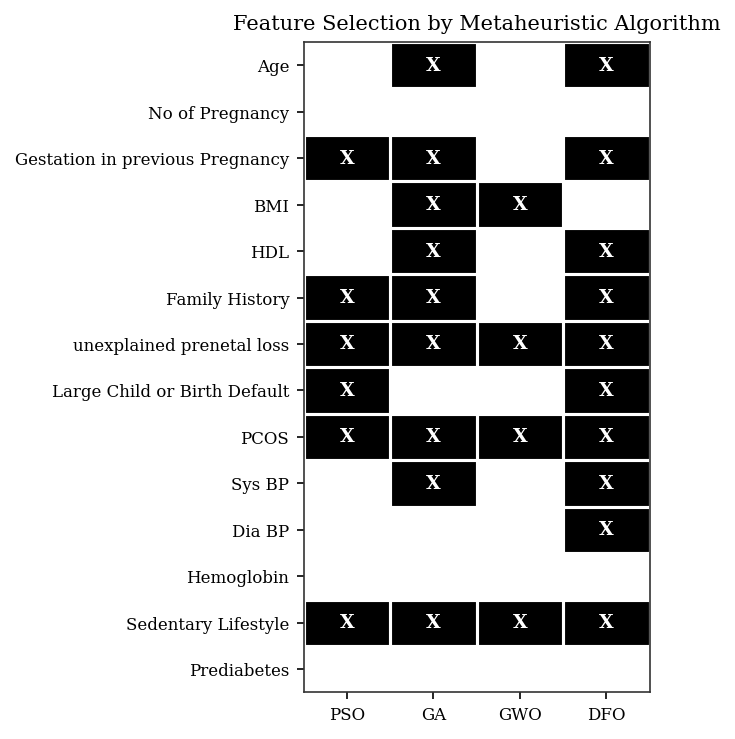

In [ ]:
algo_names = ['PSO', 'GA', 'GWO', 'DFO']
selection_matrix = pd.DataFrame({algo: results[algo].astype(int) for algo in algo_names}, index=feature_names)

fig, ax = plt.subplots(figsize=(4.5, 5))
ax.imshow(selection_matrix.values, cmap='Greys', aspect='auto', vmin=0, vmax=1)
ax.set_xticks(np.arange(len(algo_names))); ax.set_xticklabels(algo_names)
ax.set_yticks(np.arange(len(feature_names))); ax.set_yticklabels(selection_matrix.index)
ax.set_xticks(np.arange(-.5, len(algo_names), 1), minor=True)
ax.set_yticks(np.arange(-.5, len(feature_names), 1), minor=True)
ax.grid(which='minor', color='white', linewidth=1.5)
ax.tick_params(which='minor', bottom=False, left=False)
for i in range(len(feature_names)):
    for j in range(len(algo_names)):
        val = selection_matrix.values[i, j]
        ax.text(j, i, 'X' if val else '', ha='center', va='center',
                color='white' if val else 'black', fontsize=9, fontweight='bold')
ax.set_title('Feature Selection by Metaheuristic Algorithm')
plt.tight_layout()
plt.savefig('fig1_feature_selection_heatmap.pdf', bbox_inches='tight')
plt.savefig('fig1_feature_selection_heatmap.png', bbox_inches='tight')
plt.show()

**Figure 2 — Consensus scores with selection threshold**

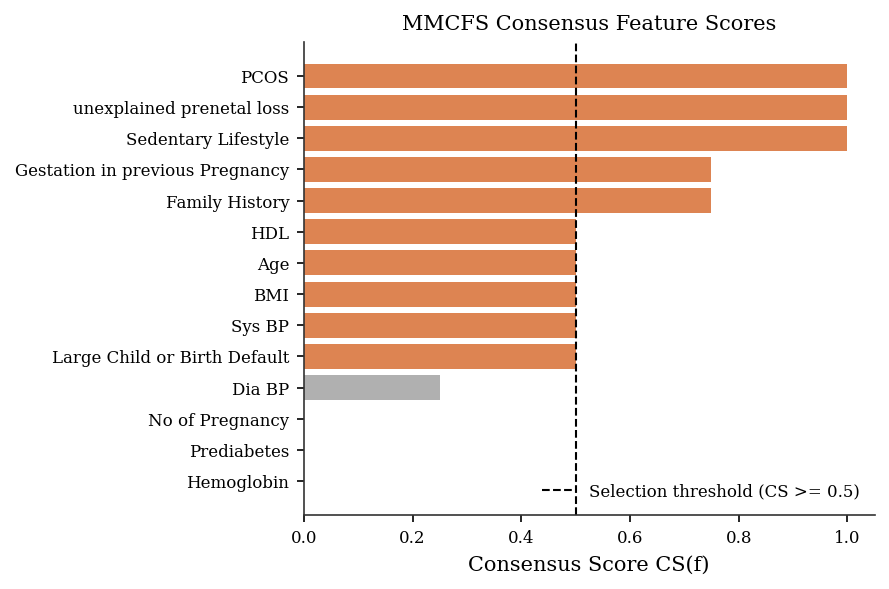

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
cs_sorted = consensus_df.sort_values('CS_rounded', ascending=True)
colors = [COLOR_MMCFS if v >= 0.5 else '#B0B0B0' for v in cs_sorted['CS_rounded']]

ax.barh(cs_sorted.index, cs_sorted['CS_rounded'], color=colors)
ax.axvline(0.5, color='black', linestyle='--', linewidth=1, label='Selection threshold (CS >= 0.5)')
ax.set_xlabel('Consensus Score CS(f)')
ax.set_title('MMCFS Consensus Feature Scores')
ax.legend(frameon=False, loc='lower right')
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('fig2_mmcfs_consensus_scores.pdf', bbox_inches='tight')
plt.savefig('fig2_mmcfs_consensus_scores.png', bbox_inches='tight')
plt.show()

**Figure 3 — Accuracy: Full vs MMCFS, all 8 models**

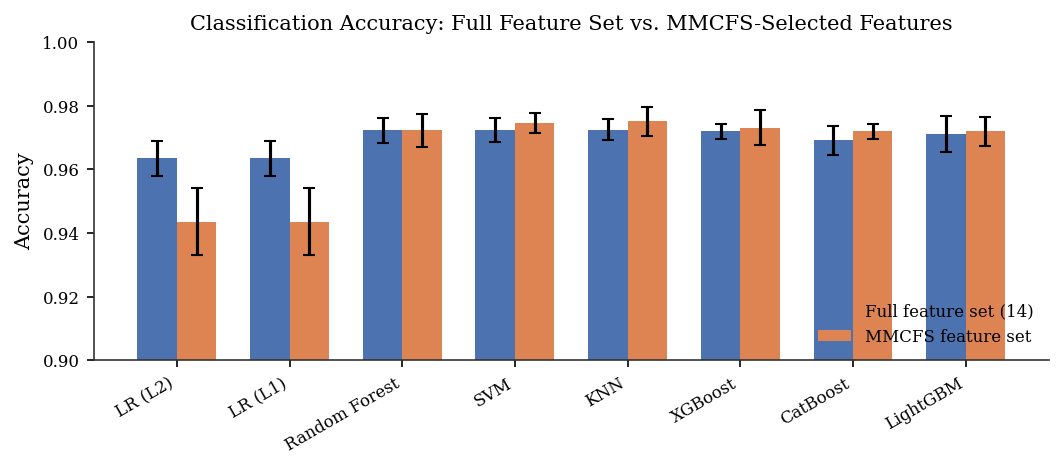

In [ ]:
full_acc = [baseline_results_full[m]['accuracy'][0] for m in models_list]
full_acc_std = [baseline_results_full[m]['accuracy'][1] for m in models_list]
mmcfs_acc = [mmcfs_results[m]['accuracy'][0] for m in models_list]
mmcfs_acc_std = [mmcfs_results[m]['accuracy'][1] for m in models_list]

x = np.arange(len(models_list)); width = 0.35
fig, ax = plt.subplots(figsize=(7.16, 3.2))
ax.bar(x - width/2, full_acc, width, yerr=full_acc_std, capsize=3, label='Full feature set (14)', color=COLOR_FULL)
ax.bar(x + width/2, mmcfs_acc, width, yerr=mmcfs_acc_std, capsize=3, label='MMCFS feature set', color=COLOR_MMCFS)
ax.set_ylabel('Accuracy'); ax.set_ylim(0.90, 1.0)
ax.set_xticks(x); ax.set_xticklabels(models_list, rotation=30, ha='right')
ax.legend(frameon=False, loc='lower right')
ax.set_title('Classification Accuracy: Full Feature Set vs. MMCFS-Selected Features')
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('fig3_accuracy_comparison.pdf', bbox_inches='tight')
plt.savefig('fig3_accuracy_comparison.png', bbox_inches='tight')
plt.show()

**Figure 4 — ROC-AUC: Full vs MMCFS**

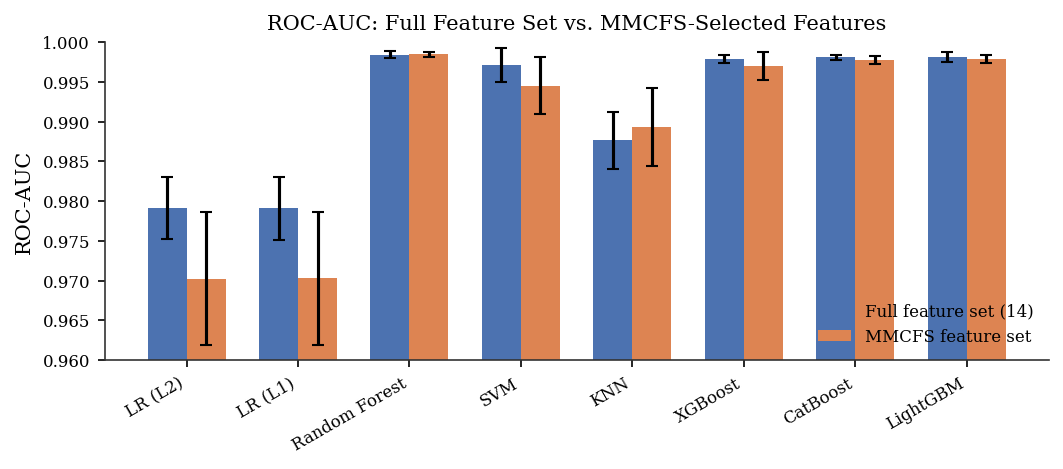

In [ ]:
full_auc = [baseline_results_full[m]['roc_auc'][0] for m in models_list]
full_auc_std = [baseline_results_full[m]['roc_auc'][1] for m in models_list]
mmcfs_auc = [mmcfs_results[m]['roc_auc'][0] for m in models_list]
mmcfs_auc_std = [mmcfs_results[m]['roc_auc'][1] for m in models_list]

fig, ax = plt.subplots(figsize=(7.16, 3.2))
ax.bar(x - width/2, full_auc, width, yerr=full_auc_std, capsize=3, label='Full feature set (14)', color=COLOR_FULL)
ax.bar(x + width/2, mmcfs_auc, width, yerr=mmcfs_auc_std, capsize=3, label='MMCFS feature set', color=COLOR_MMCFS)
ax.set_ylabel('ROC-AUC'); ax.set_ylim(0.96, 1.0)
ax.set_xticks(x); ax.set_xticklabels(models_list, rotation=30, ha='right')
ax.legend(frameon=False, loc='lower right')
ax.set_title('ROC-AUC: Full Feature Set vs. MMCFS-Selected Features')
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('fig4_auc_comparison.pdf', bbox_inches='tight')
plt.savefig('fig4_auc_comparison.png', bbox_inches='tight')
plt.show()

**Figure 5 — Per-feature standalone discriminative power**

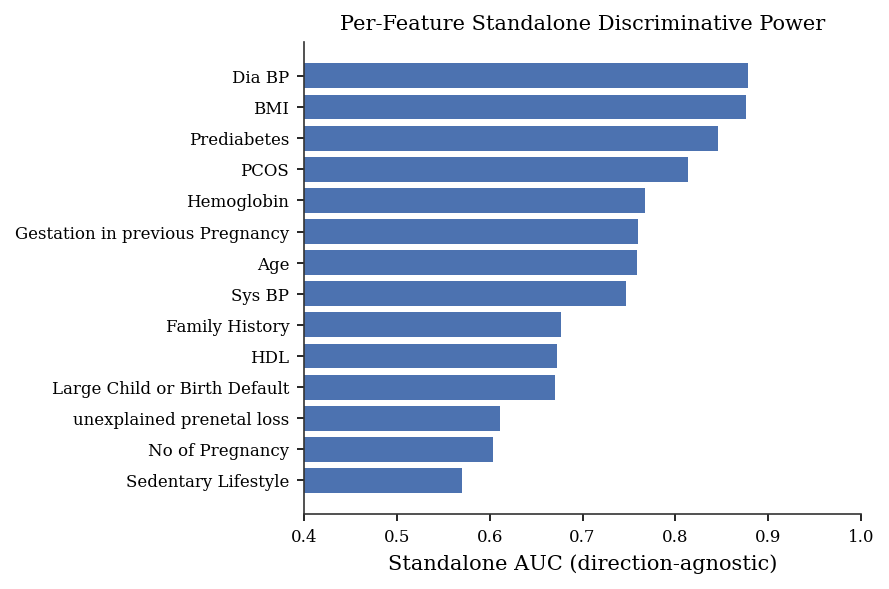

In [ ]:
auc_corrected = auc_series.apply(lambda a: max(a, 1 - a) if a is not None else None).sort_values()

fig, ax = plt.subplots(figsize=(6, 4))
ax.barh(auc_corrected.index, auc_corrected.values, color=COLOR_FULL)
ax.set_xlabel('Standalone AUC (direction-agnostic)'); ax.set_xlim(0.4, 1.0)
ax.set_title('Per-Feature Standalone Discriminative Power')
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('fig5_standalone_feature_auc.pdf', bbox_inches='tight')
plt.savefig('fig5_standalone_feature_auc.png', bbox_inches='tight')
plt.show()

**Figure 6 — Correlation: excluded vs. retained features (redundancy evidence)**

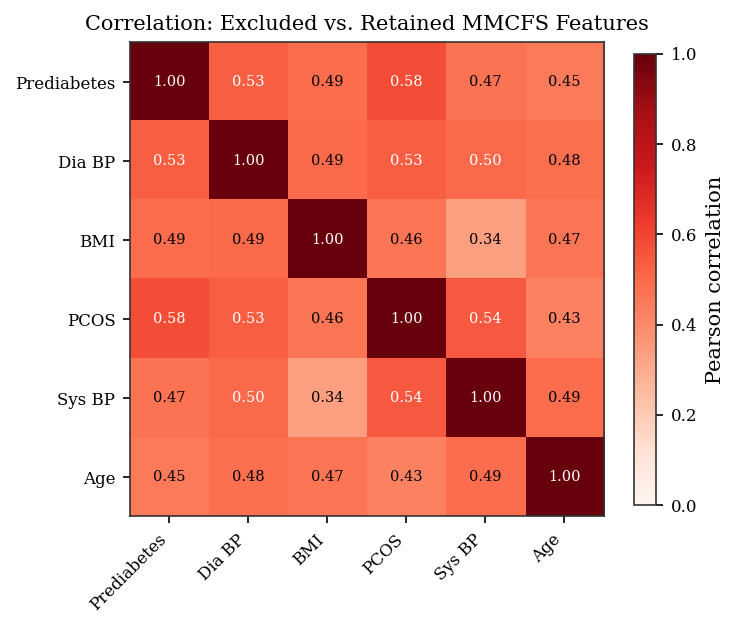

In [ ]:
corr_matrix = df[redundancy_check_cols].corr()

fig, ax = plt.subplots(figsize=(5, 4.5))
im = ax.imshow(corr_matrix.values, cmap='Reds', vmin=0, vmax=1)
ax.set_xticks(np.arange(len(redundancy_check_cols))); ax.set_xticklabels(redundancy_check_cols, rotation=45, ha='right')
ax.set_yticks(np.arange(len(redundancy_check_cols))); ax.set_yticklabels(redundancy_check_cols)
for i in range(len(redundancy_check_cols)):
    for j in range(len(redundancy_check_cols)):
        ax.text(j, i, f"{corr_matrix.values[i,j]:.2f}", ha='center', va='center', fontsize=7,
                color='white' if corr_matrix.values[i,j] > 0.5 else 'black')
fig.colorbar(im, ax=ax, shrink=0.8, label='Pearson correlation')
ax.set_title('Correlation: Excluded vs. Retained MMCFS Features')
plt.tight_layout()
plt.savefig('fig6_redundancy_correlation.pdf', bbox_inches='tight')
plt.savefig('fig6_redundancy_correlation.png', bbox_inches='tight')
plt.show()

**Figure 7 — ROC curves for top models on MMCFS set**

Uses the same `StratifiedKFold(shuffle=True, random_state=42)` as `evaluate_model`, so the AUCs here match Table 2 — using an unmatched/unshuffled CV here previously caused a mismatch, now fixed.

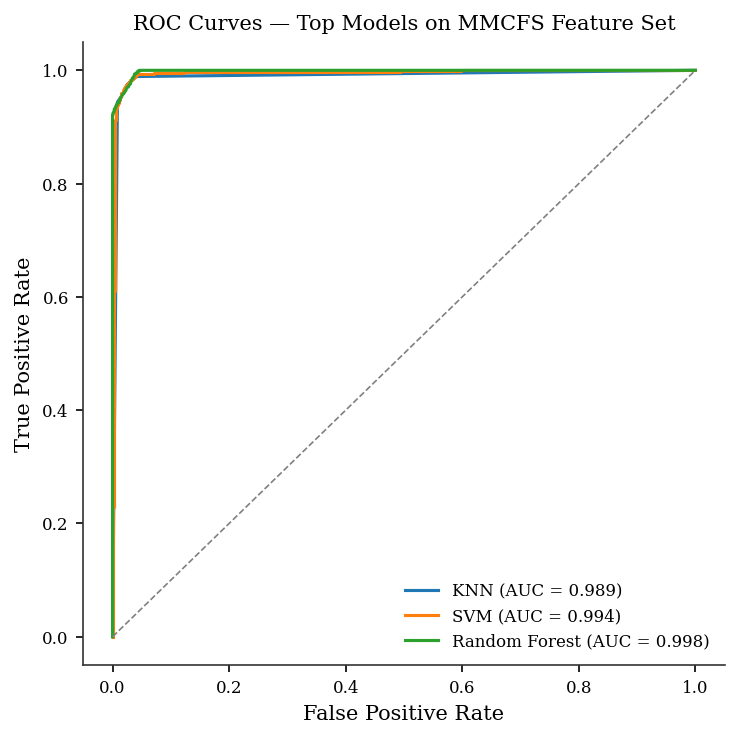

In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_curve, auc

cv_matched = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

top_models = {
    'KNN': KNeighborsClassifier(),
    'SVM': SVC(probability=True, random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
}

fig, ax = plt.subplots(figsize=(5, 5))
for name, clf in top_models.items():
    probs = cross_val_predict(clf, X_mmcfs, y, cv=cv_matched, method='predict_proba')[:, 1]
    fpr, tpr, _ = roc_curve(y, probs)
    roc_auc_val = auc(fpr, tpr)
    ax.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc_val:.3f})')

ax.plot([0, 1], [0, 1], color='gray', linestyle='--', linewidth=0.8)
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves — Top Models on MMCFS Feature Set')
ax.legend(frameon=False, loc='lower right')
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('fig7_roc_curves.pdf', bbox_inches='tight')
plt.savefig('fig7_roc_curves.png', bbox_inches='tight')
plt.show()

**10. Nested Cross-Validation — fixes feature-selection leakage**

In [ ]:
# ============================================================
# 10. Nested Cross-Validation — fixes feature-selection leakage
# ============================================================
# Problem: MMCFS above was run ONCE on the full dataset before evaluation,
# meaning feature selection technically "saw" data later used for testing.
# Fix: re-run the ENTIRE MMCFS pipeline separately inside each outer fold,
# using only that fold's training data.

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

SEED = 42
cols_to_impute = ['BMI', 'HDL', 'Sys BP']

# Reload fresh, pre-imputed, pre-scaled raw data
path = kagglehub.dataset_download("sumathisanthosh/gestational-diabetes-mellitus-gdm-data-set")
df_raw = pd.read_excel(os.path.join(path, "Gestational Diabetic Dat Set.xlsx"))
df_raw = df_raw.drop(columns=['Case Number', 'OGTT'])

X_raw = df_raw.drop(columns=[label_column]).copy()
y_raw = df_raw[label_column].copy()

def run_mmcfs_on_training_data(X_train_scaled, y_train, feat_names, seed):
    """Runs PSO/GA/GWO/DFO + consensus scoring on TRAINING DATA ONLY."""
    n_feat = X_train_scaled.shape[1]

    def fitness_function(solution):
        selected = solution > 0.5
        if selected.sum() == 0:
            return 1.0
        X_sub = X_train_scaled[:, selected]
        clf = KNeighborsClassifier(n_neighbors=5)
        inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=seed)
        scores = cross_val_score(clf, X_sub, y_train, cv=inner_cv, scoring='accuracy')
        return -scores.mean()

    problem = {
        "obj_func": fitness_function,
        "bounds": FloatVar(lb=[0.0]*n_feat, ub=[1.0]*n_feat),
        "minmax": "min",
    }

    masks = {}
    masks['PSO'] = OriginalPSO(epoch=30, pop_size=20).solve(problem, seed=seed).solution > 0.5
    masks['GA']  = BaseGA(epoch=30, pop_size=20).solve(problem, seed=seed).solution > 0.5
    masks['GWO'] = OriginalGWO(epoch=30, pop_size=20).solve(problem, seed=seed).solution > 0.5
    masks['DFO'] = OriginalDO(epoch=30, pop_size=20).solve(problem, seed=seed).solution > 0.5

    weights = {}
    for algo, mask in masks.items():
        if mask.sum() == 0:
            weights[algo] = 0
            continue
        X_sub = X_train_scaled[:, mask]
        clf = XGBClassifier(eval_metric='logloss', random_state=seed)
        inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
        weights[algo] = cross_val_score(clf, X_sub, y_train, cv=inner_cv, scoring='accuracy').mean()

    total_w = sum(weights.values())
    norm_w = {k: v/total_w for k, v in weights.items()} if total_w > 0 else {k: 0.25 for k in weights}

    cs = np.zeros(n_feat)
    for algo, mask in masks.items():
        cs += norm_w[algo] * mask.astype(float)
    cs = np.round(cs, 3)

    selected = [feat_names[i] for i in range(n_feat) if cs[i] >= 0.5]
    return selected, masks, norm_w, cs

# ============================================================
# NESTED CV MAIN LOOP
# ============================================================
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
fold_results = []
fold_selected_features = []
feat_name_list = X_raw.columns.tolist()

for fold_idx, (train_idx, test_idx) in enumerate(outer_cv.split(X_raw, y_raw)):
    print(f"\n{'='*20} OUTER FOLD {fold_idx+1}/5 {'='*20}")

    X_train_raw = X_raw.iloc[train_idx].copy()
    X_test_raw  = X_raw.iloc[test_idx].copy()
    y_train, y_test = y_raw.iloc[train_idx], y_raw.iloc[test_idx]

    # Impute — fit on TRAIN only
    for col in cols_to_impute:
        median_val = X_train_raw[col].median()
        X_train_raw[col] = X_train_raw[col].fillna(median_val)
        X_test_raw[col] = X_test_raw[col].fillna(median_val)

    # Scale — fit on TRAIN only
    fold_scaler = StandardScaler()
    X_train_scaled = fold_scaler.fit_transform(X_train_raw)
    X_test_scaled = fold_scaler.transform(X_test_raw)

    # MMCFS — run on TRAIN only
    selected_feats, masks, weights, cs = run_mmcfs_on_training_data(
        X_train_scaled, y_train.values, feat_name_list, seed=SEED + fold_idx
    )
    print(f"Selected {len(selected_feats)} features: {selected_feats}")
    fold_selected_features.append(selected_feats)

    feat_idx = [feat_name_list.index(f) for f in selected_feats]
    X_train_final = X_train_scaled[:, feat_idx]
    X_test_final = X_test_scaled[:, feat_idx]

    clf = RandomForestClassifier(random_state=SEED)
    clf.fit(X_train_final, y_train)
    y_pred = clf.predict(X_test_final)
    y_proba = clf.predict_proba(X_test_final)[:, 1]

    fold_metrics = {
        'fold': fold_idx + 1, 'n_features': len(selected_feats),
        'accuracy': accuracy_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred),
        'recall': recall_score(y_test, y_pred),
        'f1': f1_score(y_test, y_pred),
        'roc_auc': roc_auc_score(y_test, y_proba)
    }
    fold_results.append(fold_metrics)
    print(fold_metrics)

# ============================================================
# SUMMARY + STABILITY ANALYSIS
# ============================================================
nested_results_df = pd.DataFrame(fold_results)
print("\n\n=== NESTED CV SUMMARY (Random Forest, MMCFS re-run per fold) ===")
for metric in ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']:
    print(f"{metric.capitalize():10s}: {nested_results_df[metric].mean():.4f} +/- {nested_results_df[metric].std():.4f}")

print("\n=== Feature selection per fold (stability analysis) ===")
for i, feats in enumerate(fold_selected_features):
    print(f"Fold {i+1} ({len(feats)} features): {feats}")

print("\n=== Selection frequency across 5 outer folds ===")
all_selections = [f for fold_feats in fold_selected_features for f in fold_feats]
freq = pd.Series(all_selections).value_counts()
print(freq)

Using Colab cache for faster access to the 'gestational-diabetes-mellitus-gdm-data-set' dataset.


INFO:mealpy.swarm_based.PSO.OriginalPSO:OriginalPSO(epoch=30, pop_size=20, c1=2.05, c2=2.05, w=0.4)



==================== OUTER FOLD 1/5 ====================


INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 1, Current best: -0.9734042553191489, Global best: -0.9734042553191489, Runtime: 0.75040 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 2, Current best: -0.9734042553191489, Global best: -0.9734042553191489, Runtime: 0.69732 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 3, Current best: -0.973758865248227, Global best: -0.973758865248227, Runtime: 0.68950 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 4, Current best: -0.974113475177305, Global best: -0.974113475177305, Runtime: 0.80842 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 5, Current best: -0.974113475177305, Global best: -0.974113475177305, Runtime: 0.92766 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 6, Current best: -0.975177304964539, Global best: -0.975177304964539, Runtime: 0.89393 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P,

Selected 10 features: ['Age', 'No of Pregnancy', 'Gestation in previous Pregnancy', 'BMI', 'Family History', 'unexplained prenetal loss', 'Large Child or Birth Default', 'Sys BP', 'Sedentary Lifestyle', 'Prediabetes']


INFO:mealpy.swarm_based.PSO.OriginalPSO:OriginalPSO(epoch=30, pop_size=20, c1=2.05, c2=2.05, w=0.4)


... (11 outputs left out)

INFO:mealpy.swarm_based.PSO.OriginalPSO:OriginalPSO(epoch=30, pop_size=20, c1=2.05, c2=2.05, w=0.4)


{'fold': 4, 'n_features': 12, 'accuracy': 0.9744680851063829, 'precision': 0.9605734767025089, 'recall': 0.9745454545454545, 'f1': 0.9675090252707581, 'roc_auc': np.float64(0.9985412262156448)}

==================== OUTER FOLD 5/5 ====================


INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 1, Current best: -0.9748226950354609, Global best: -0.9748226950354609, Runtime: 0.67515 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 2, Current best: -0.9748226950354609, Global best: -0.9748226950354609, Runtime: 0.65214 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 3, Current best: -0.9748226950354609, Global best: -0.9748226950354609, Runtime: 0.63002 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 4, Current best: -0.9762411347517731, Global best: -0.9762411347517731, Runtime: 0.64544 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 5, Current best: -0.9762411347517731, Global best: -0.9762411347517731, Runtime: 0.69109 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Problem: P, Epoch: 6, Current best: -0.9762411347517731, Global best: -0.9762411347517731, Runtime: 1.02114 seconds
INFO:mealpy.swarm_based.PSO.OriginalPSO:>>>Pro

Selected 10 features: ['Age', 'No of Pregnancy', 'Gestation in previous Pregnancy', 'HDL', 'Family History', 'unexplained prenetal loss', 'Large Child or Birth Default', 'PCOS', 'Sedentary Lifestyle', 'Prediabetes']
{'fold': 5, 'n_features': 10, 'accuracy': 0.9787234042553191, 'precision': 0.9642857142857143, 'recall': 0.9818181818181818, 'f1': 0.972972972972973, 'roc_auc': np.float64(0.9984101479915433)}


=== NESTED CV SUMMARY (Random Forest, MMCFS re-run per fold) ===
Accuracy  : 0.9722 +/- 0.0055
Precision : 0.9556 +/- 0.0074
Recall    : 0.9738 +/- 0.0070
F1        : 0.9646 +/- 0.0071
Roc_auc   : 0.9981 +/- 0.0007

=== Feature selection per fold (stability analysis) ===
Fold 1 (10 features): ['Age', 'No of Pregnancy', 'Gestation in previous Pregnancy', 'BMI', 'Family History', 'unexplained prenetal loss', 'Large Child or Birth Default', 'Sys BP', 'Sedentary Lifestyle', 'Prediabetes']
Fold 2 (10 features): ['Age', 'Gestation in previous Pregnancy', 'BMI', 'HDL', 'Family History', 'L

**Prediabetes Incremental Ablation (nested CV)**

In [ ]:
def evaluate_feature_set_nested(X_raw, y_raw, feature_subset, cols_to_impute, seed=42, n_splits=5):
    outer_cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    fold_metrics = []

    for fold_idx, (train_idx, test_idx) in enumerate(outer_cv.split(X_raw, y_raw)):
        X_train_raw = X_raw.iloc[train_idx][feature_subset].copy()
        X_test_raw  = X_raw.iloc[test_idx][feature_subset].copy()
        y_train, y_test = y_raw.iloc[train_idx], y_raw.iloc[test_idx]

        for col in [c for c in cols_to_impute if c in feature_subset]:
            median_val = X_train_raw[col].median()
            X_train_raw[col] = X_train_raw[col].fillna(median_val)
            X_test_raw[col] = X_test_raw[col].fillna(median_val)

        fold_scaler = StandardScaler()
        X_train_scaled = fold_scaler.fit_transform(X_train_raw)
        X_test_scaled = fold_scaler.transform(X_test_raw)

        clf = RandomForestClassifier(random_state=seed)
        clf.fit(X_train_scaled, y_train)
        y_pred = clf.predict(X_test_scaled)
        y_proba = clf.predict_proba(X_test_scaled)[:, 1]

        fold_metrics.append({
            'accuracy': accuracy_score(y_test, y_pred),
            'precision': precision_score(y_test, y_pred),
            'recall': recall_score(y_test, y_pred),
            'f1': f1_score(y_test, y_pred),
            'roc_auc': roc_auc_score(y_test, y_proba)
        })

    return pd.DataFrame(fold_metrics)

mmcfs_stable_core = ['Age', 'Prediabetes', 'Sedentary Lifestyle',
    'Gestation in previous Pregnancy', 'BMI', 'Sys BP', 'Family History',
    'Large Child or Birth Default', 'unexplained prenetal loss', 'PCOS']

variants = {
    'MMCFS (with Prediabetes)': mmcfs_stable_core,
    'MMCFS − Prediabetes': [f for f in mmcfs_stable_core if f != 'Prediabetes'],
    'MMCFS − Prediabetes + Dia BP': [f for f in mmcfs_stable_core if f != 'Prediabetes'] + ['Dia BP'],
    'Full 14 features': feat_name_list
}

print("=== Prediabetes Incremental Ablation (Nested CV, Random Forest) ===\n")
ablation_results = {}
for name, feats in variants.items():
    result_df = evaluate_feature_set_nested(X_raw, y_raw, feats, cols_to_impute, seed=42)
    ablation_results[name] = result_df
    print(f"--- {name} ({len(feats)} features) ---")
    for metric in ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']:
        print(f"{metric.capitalize():10s}: {result_df[metric].mean():.4f} +/- {result_df[metric].std():.4f}")
    print()

=== Prediabetes Incremental Ablation (Nested CV, Random Forest) ===

--- MMCFS (with Prediabetes) (10 features) ---
Accuracy  : 0.9750 +/- 0.0026
Precision : 0.9593 +/- 0.0049
Recall    : 0.9774 +/- 0.0098
F1        : 0.9682 +/- 0.0034
Roc_auc   : 0.9984 +/- 0.0003

--- MMCFS − Prediabetes (9 features) ---
Accuracy  : 0.9748 +/- 0.0025
Precision : 0.9573 +/- 0.0038
Recall    : 0.9789 +/- 0.0101
F1        : 0.9679 +/- 0.0034
Roc_auc   : 0.9984 +/- 0.0003

--- MMCFS − Prediabetes + Dia BP (10 features) ---
Accuracy  : 0.9730 +/- 0.0017
Precision : 0.9513 +/- 0.0034
Recall    : 0.9811 +/- 0.0079
F1        : 0.9659 +/- 0.0024
Roc_auc   : 0.9984 +/- 0.0004

--- Full 14 features (14 features) ---
Accuracy  : 0.9730 +/- 0.0040
Precision : 0.9571 +/- 0.0079
Recall    : 0.9745 +/- 0.0085
F1        : 0.9657 +/- 0.0051
Roc_auc   : 0.9984 +/- 0.0005



**Missingness-Indicator Ablation (nested CV)**

In [ ]:
def evaluate_with_missingness_indicators(X_raw_full, y_raw, cols_with_missing, use_indicators, seed=42, n_splits=5):
    outer_cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    fold_metrics = []

    for fold_idx, (train_idx, test_idx) in enumerate(outer_cv.split(X_raw_full, y_raw)):
        X_train_raw = X_raw_full.iloc[train_idx].copy()
        X_test_raw  = X_raw_full.iloc[test_idx].copy()
        y_train, y_test = y_raw.iloc[train_idx], y_raw.iloc[test_idx]

        if use_indicators:
            for col in cols_with_missing:
                X_train_raw[f'{col}_was_missing'] = X_train_raw[col].isnull().astype(int)
                X_test_raw[f'{col}_was_missing'] = X_test_raw[col].isnull().astype(int)

        for col in cols_with_missing:
            median_val = X_train_raw[col].median()
            X_train_raw[col] = X_train_raw[col].fillna(median_val)
            X_test_raw[col] = X_test_raw[col].fillna(median_val)

        fold_scaler = StandardScaler()
        X_train_scaled = fold_scaler.fit_transform(X_train_raw)
        X_test_scaled = fold_scaler.transform(X_test_raw)

        clf = RandomForestClassifier(random_state=seed)
        clf.fit(X_train_scaled, y_train)
        y_pred = clf.predict(X_test_scaled)
        y_proba = clf.predict_proba(X_test_scaled)[:, 1]

        fold_metrics.append({
            'accuracy': accuracy_score(y_test, y_pred),
            'precision': precision_score(y_test, y_pred),
            'recall': recall_score(y_test, y_pred),
            'f1': f1_score(y_test, y_pred),
            'roc_auc': roc_auc_score(y_test, y_proba)
        })

    return pd.DataFrame(fold_metrics)

cols_with_missing = ['BMI', 'HDL', 'Sys BP']

print("=== Missingness-Indicator Ablation (Nested CV, Random Forest, all 14 features) ===\n")

print("--- A. Median imputation ONLY (no indicators) ---")
result_a = evaluate_with_missingness_indicators(X_raw, y_raw, cols_with_missing, use_indicators=False, seed=42)
for metric in ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']:
    print(f"{metric.capitalize():10s}: {result_a[metric].mean():.4f} +/- {result_a[metric].std():.4f}")

print("\n--- B. Median imputation + missingness indicators ---")
result_b = evaluate_with_missingness_indicators(X_raw, y_raw, cols_with_missing, use_indicators=True, seed=42)
for metric in ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']:
    print(f"{metric.capitalize():10s}: {result_b[metric].mean():.4f} +/- {result_b[metric].std():.4f}")

print(f"\nAccuracy difference (B - A): {result_b['accuracy'].mean() - result_a['accuracy'].mean():.4f}")
print(f"ROC-AUC difference (B - A): {result_b['roc_auc'].mean() - result_a['roc_auc'].mean():.4f}")

=== Missingness-Indicator Ablation (Nested CV, Random Forest, all 14 features) ===

--- A. Median imputation ONLY (no indicators) ---
Accuracy  : 0.9730 +/- 0.0040
Precision : 0.9571 +/- 0.0079
Recall    : 0.9745 +/- 0.0085
F1        : 0.9657 +/- 0.0051
Roc_auc   : 0.9984 +/- 0.0005

--- B. Median imputation + missingness indicators ---
Accuracy  : 0.9699 +/- 0.0059
Precision : 0.9561 +/- 0.0074
Recall    : 0.9672 +/- 0.0178
F1        : 0.9615 +/- 0.0079
Roc_auc   : 0.9982 +/- 0.0006

Accuracy difference (B - A): -0.0031
ROC-AUC difference (B - A): -0.0002


**TabPFN v2**

In [ ]:
!pip install tabpfn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 827.5/827.5 kB 16.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 595.9/595.9 kB 45.6 MB/s eta 0:00:00


In [ ]:
import os

# Set the token (paste your real key between the quotes)
os.environ["TABPFN_TOKEN"] = "tabpfn_sk_MdfSQWW3f7snbRF9MztXAiw2xzV6lg9c7spHv2MSD84"

# Verify immediately, in the same cell
print("Token is set:", "TABPFN_TOKEN" in os.environ)
print("Token value (first 8 chars):", os.environ.get("TABPFN_TOKEN", "NOT SET")[:8])



Token is set: True
Token value (first 8 chars): tabpfn_s


In [ ]:


from tabpfn import TabPFNClassifier

X_mmcfs_final = df[mmcfs_stable_core].copy()
for col in [c for c in cols_to_impute if c in mmcfs_stable_core]:
    X_mmcfs_final[col] = X_mmcfs_final[col].fillna(X_mmcfs_final[col].median())
y_final = df[label_column]

scaler_final = StandardScaler()
X_mmcfs_final_scaled = scaler_final.fit_transform(X_mmcfs_final)

print("=== TabPFN v2 — MMCFS Feature Set (10 features) ===")

evaluate_model(TabPFNClassifier(), X_mmcfs_final_scaled, y_final, "TabPFN v2 - MMCFS")

print("\n=== TabPFN v2 — Full Feature Set (14 features) ===")
evaluate_model(TabPFNClassifier(), X_scaled, y, "TabPFN v2 - Full")

=== TabPFN v2 — MMCFS Feature Set (10 features) ===


tabpfn-v3.5-20260909.safetensors: reconstructing file:   0%|          |  0.00B /  876MB            

tabpfn-v3.5-20260909.safetensors: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/36.0 [00:00<?, ?B/s]


=== TabPFN v2 - MMCFS ===
Accuracy  : 0.9711 +/- 0.0083
Precision : 0.9726 +/- 0.0084
Recall    : 0.9526 +/- 0.0215
F1        : 0.9623 +/- 0.0110
Roc_auc   : 0.9983 +/- 0.0006

=== TabPFN v2 — Full Feature Set (14 features) ===

=== TabPFN v2 - Full ===
Accuracy  : 0.9691 +/- 0.0036
Precision : 0.9772 +/- 0.0155
Recall    : 0.9432 +/- 0.0216
F1        : 0.9595 +/- 0.0052
Roc_auc   : 0.9981 +/- 0.0005


{'accuracy': (np.float64(0.9690780141843971),
  np.float64(0.003632978290742047)),
 'precision': (np.float64(0.9771709940387993),
  np.float64(0.015549256682080983)),
 'recall': (np.float64(0.9431718646317186), np.float64(0.021648603067592902)),
 'f1': (np.float64(0.9595245707758986), np.float64(0.005187357192369231)),
 'roc_auc': (np.float64(0.9981364762101755),
  np.float64(0.0004967975106610088))}

**SHAP (on Random Forest, MMCFS feature set):**

In [ ]:
!pip install shap


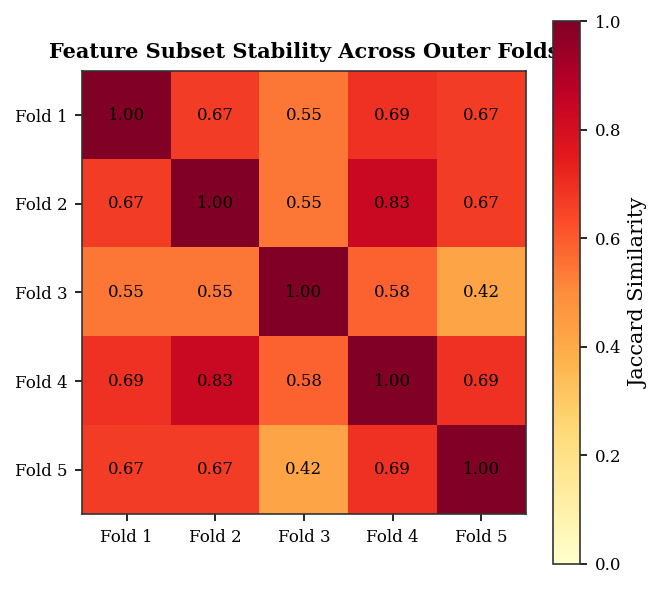

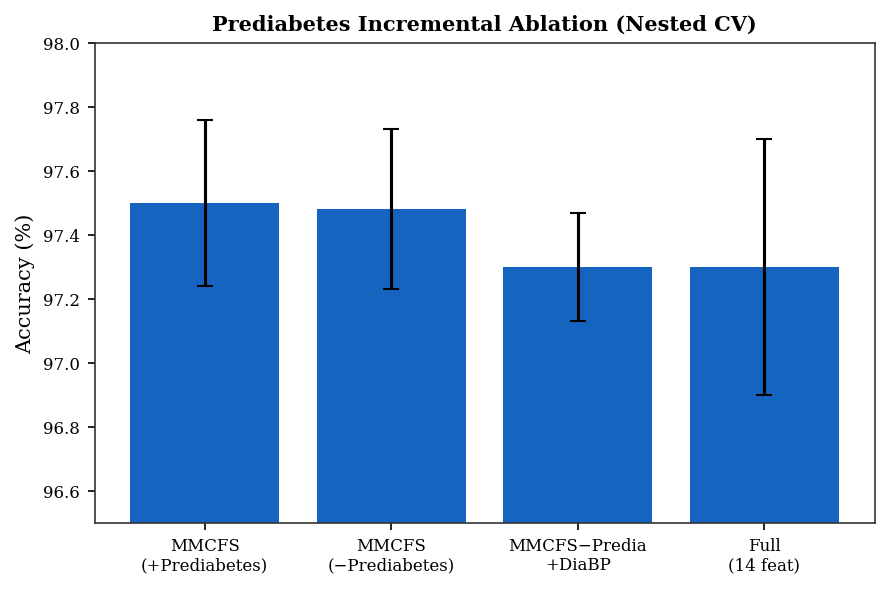

In [ ]:
# ============================================================
# NEW FIGURE — Jaccard Stability Heatmap (pairwise fold similarity)
# ============================================================
jaccard_matrix = np.array([
    [1.000, 0.667, 0.545, 0.692, 0.667],
    [0.667, 1.000, 0.545, 0.833, 0.667],
    [0.545, 0.545, 1.000, 0.583, 0.417],
    [0.692, 0.833, 0.583, 1.000, 0.692],
    [0.667, 0.667, 0.417, 0.692, 1.000]
])
fold_labels = ['Fold 1','Fold 2','Fold 3','Fold 4','Fold 5']

fig, ax = plt.subplots(figsize=(4.5, 4))
im = ax.imshow(jaccard_matrix, cmap='YlOrRd', vmin=0, vmax=1)
ax.set_xticks(range(5)); ax.set_xticklabels(fold_labels)
ax.set_yticks(range(5)); ax.set_yticklabels(fold_labels)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{jaccard_matrix[i,j]:.2f}", ha='center', va='center', fontsize=8)
plt.colorbar(im, ax=ax, label='Jaccard Similarity')
ax.set_title('Feature Subset Stability Across Outer Folds', fontweight='bold', fontsize=10)
plt.tight_layout(); plt.savefig('fig_jaccard_stability.png', dpi=300, bbox_inches='tight'); plt.show()


# ============================================================
# NEW FIGURE — Prediabetes Ablation (4-variant comparison)
# ============================================================
variants = ['MMCFS\n(+Prediabetes)','MMCFS\n(−Prediabetes)','MMCFS−Predia\n+DiaBP','Full\n(14 feat)']
acc = [97.50, 97.48, 97.30, 97.30]
err = [0.26, 0.25, 0.17, 0.40]

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(variants, acc, yerr=err, capsize=4, color='#1565C0')
ax.set_ylabel('Accuracy (%)')
ax.set_ylim(96.5, 98)
ax.set_title('Prediabetes Incremental Ablation (Nested CV)', fontweight='bold')
plt.tight_layout(); plt.savefig('fig_prediabetes_ablation.png', dpi=300, bbox_inches='tight'); plt.show()

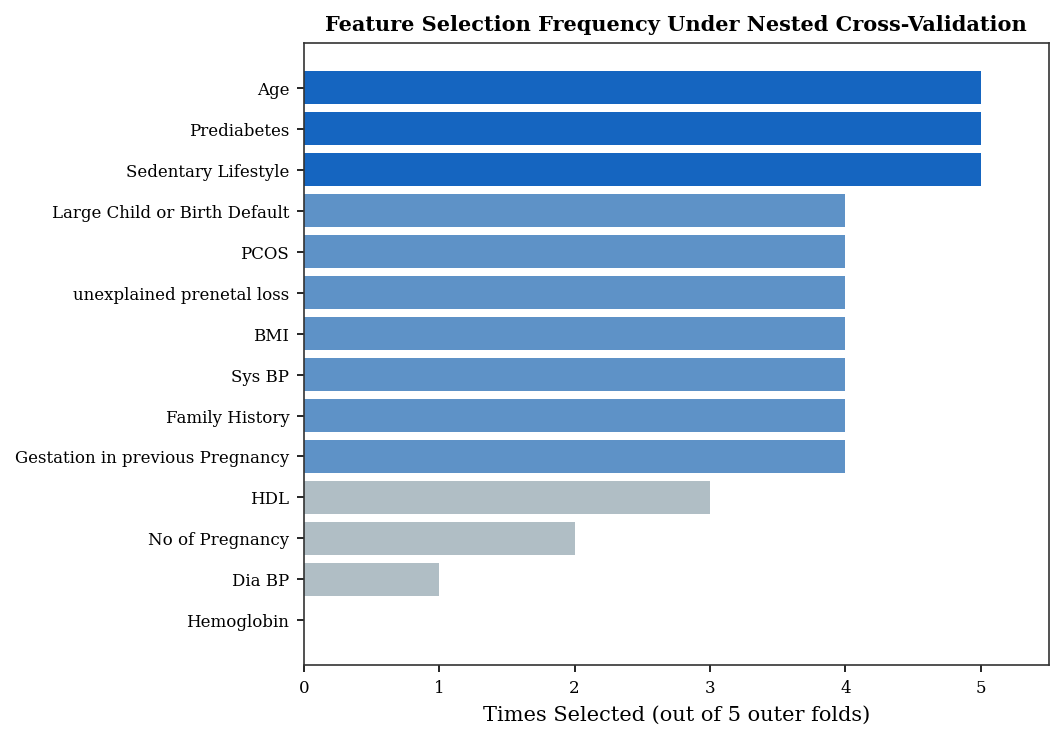

In [ ]:
# Figure 4 — Selection Frequency
freq_data = {'Age':5,'Prediabetes':5,'Sedentary Lifestyle':5,'Gestation in previous Pregnancy':4,
    'BMI':4,'Sys BP':4,'Family History':4,'Large Child or Birth Default':4,
    'unexplained prenetal loss':4,'PCOS':4,'HDL':3,'No of Pregnancy':2,'Dia BP':1,'Hemoglobin':0}
freq_series = pd.Series(freq_data).sort_values()
fig, ax = plt.subplots(figsize=(7.16, 5))
colors = ['#1565C0' if v==5 else '#5E92C7' if v>=4 else '#B0BEC5' for v in freq_series.values]
ax.barh(freq_series.index, freq_series.values, color=colors)
ax.set_xlabel('Times Selected (out of 5 outer folds)'); ax.set_xlim(0,5.5)
ax.set_title('Feature Selection Frequency Under Nested Cross-Validation', fontweight='bold')
plt.tight_layout(); plt.savefig('fig4_selection_frequency.png', dpi=300, bbox_inches='tight'); plt.show()

# Figure 5 — Jaccard Stability Heatmap (use your actual computed matrix once done running)

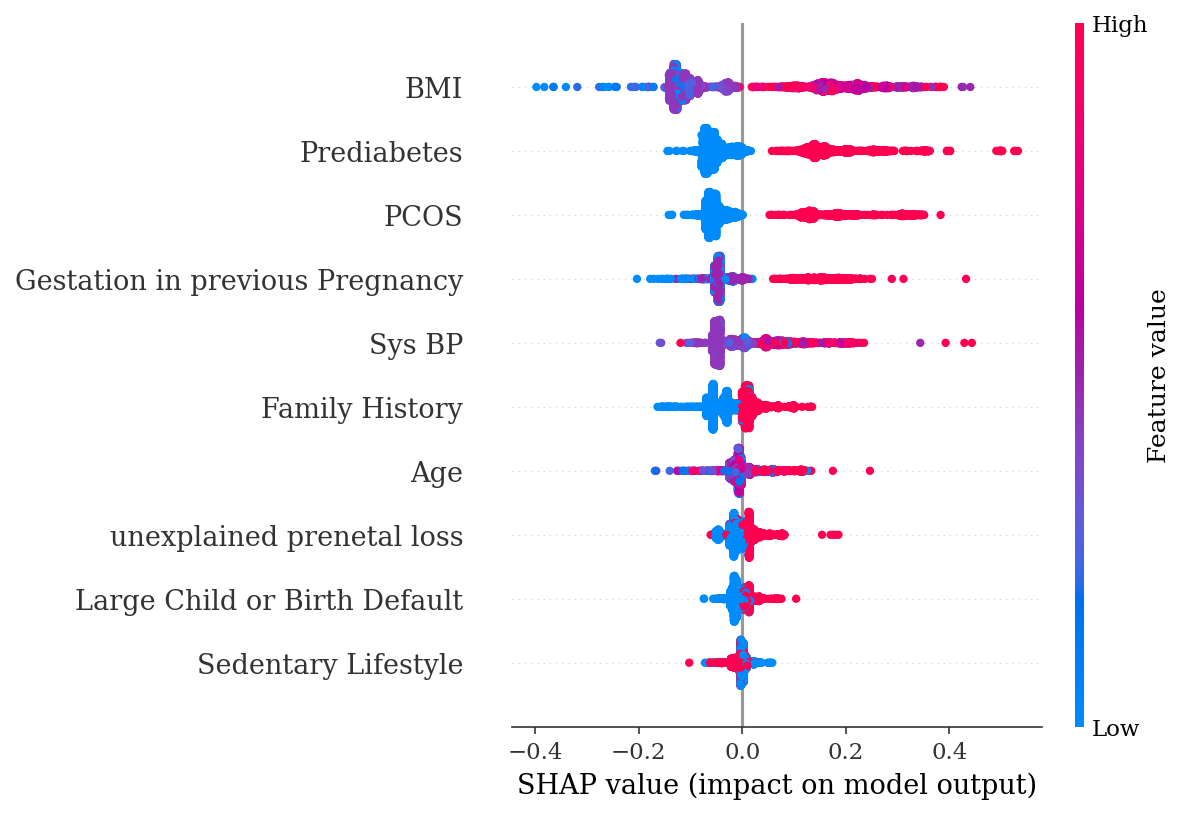

BMI                                0.137756
Prediabetes                        0.089883
PCOS                               0.085694
Gestation in previous Pregnancy    0.069764
Sys BP                             0.052831
Family History                     0.030066
Age                                0.018943
unexplained prenetal loss          0.017393
Large Child or Birth Default       0.012838
Sedentary Lifestyle                0.007584
dtype: float64


In [ ]:
best_model_unscaled = RandomForestClassifier(random_state=42)
best_model_unscaled.fit(X_mmcfs_final, y_final)  # unscaled — RF doesn't need scaling
explainer = shap.TreeExplainer(best_model_unscaled)
shap_values = explainer.shap_values(X_mmcfs_final)
shap_vals_pos = shap_values[1] if isinstance(shap_values, list) else shap_values[:,:,1]
shap.summary_plot(shap_vals_pos, X_mmcfs_final, show=False)
plt.tight_layout(); plt.savefig('fig6_shap_summary.png', dpi=300, bbox_inches='tight'); plt.show()
mean_abs_shap = pd.Series(np.abs(shap_vals_pos).mean(axis=0), index=X_mmcfs_final.columns).sort_values(ascending=False)
print(mean_abs_shap)  # exact values for Table text, not read off the plot

In [ ]:
print("Number of features:", len(mmcfs_stable_core))

Number of features: 10


In [ ]:
!pip install -q qiskit qiskit-machine-learning qiskit-algorithms

import time, numpy as np, pandas as pd
from qiskit.circuit.library import ZZFeatureMap
from qiskit_machine_learning.kernels import FidelityQuantumKernel
from qiskit_machine_learning.algorithms import QSVC
from sklearn.svm import SVC
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Data
X_q = df[mmcfs_stable_core].copy()
for col in [c for c in cols_to_impute if c in mmcfs_stable_core]:
    X_q[col] = X_q[col].fillna(X_q[col].median())
y_q = df[label_column].values

# Fast pilot: 100 samples
X_sub, _, y_sub, _ = train_test_split(
    X_q, y_q, train_size=100, stratify=y_q, random_state=42
)

# Scale → 10 features = 10 qubits
X_scaled = MinMaxScaler((0, np.pi)).fit_transform(X_sub)
n_qubits = X_scaled.shape[1]

print(f"Samples: 100 | Features: {n_qubits} | Qubits: {n_qubits}")

# Quantum kernel
feature_map = ZZFeatureMap(
    feature_dimension=n_qubits,
    reps=1,
    entanglement='linear'
)
quantum_kernel = FidelityQuantumKernel(feature_map=feature_map)

# 3-fold CV
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
q_results, c_results = [], []

start = time.time()

for fold, (tr, te) in enumerate(cv.split(X_scaled, y_sub), 1):

    Xtr, Xte = X_scaled[tr], X_scaled[te]
    ytr, yte = y_sub[tr], y_sub[te]

    # QSVM
    qsvc = QSVC(quantum_kernel=quantum_kernel)
    qsvc.fit(Xtr, ytr)
    qp = qsvc.predict(Xte)

    try:
        qs = qsvc.decision_function(Xte)
    except:
        qs = qp

    q_results.append([
        accuracy_score(yte, qp),
        precision_score(yte, qp, zero_division=0),
        recall_score(yte, qp, zero_division=0),
        f1_score(yte, qp, zero_division=0),
        roc_auc_score(yte, qs)
    ])

    # Classical RBF SVM
    svc = SVC(kernel='rbf', probability=True, random_state=42)
    svc.fit(Xtr, ytr)
    cp = svc.predict(Xte)
    cs = svc.predict_proba(Xte)[:, 1]

    c_results.append([
        accuracy_score(yte, cp),
        precision_score(yte, cp, zero_division=0),
        recall_score(yte, cp, zero_division=0),
        f1_score(yte, cp, zero_division=0),
        roc_auc_score(yte, cs)
    ])

    print(f"Fold {fold}: QSVM Acc={q_results[-1][0]:.4f} | "
          f"Classical Acc={c_results[-1][0]:.4f}")

# Results
metrics = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']

q_df = pd.DataFrame(q_results, columns=metrics)
c_df = pd.DataFrame(c_results, columns=metrics)

print(f"\nRuntime: {(time.time()-start)/60:.2f} minutes")

print("\nQSVM:")
for m in metrics:
    print(f"{m:10s}: {q_df[m].mean():.4f} ± {q_df[m].std():.4f}")

print("\nClassical RBF SVM:")
for m in metrics:
    print(f"{m:10s}: {c_df[m].mean():.4f} ± {c_df[m].std():.4f}")

q_df.to_csv("qsvm_pilot_results.csv", index=False)
c_df.to_csv("classical_svm_pilot_results.csv", index=False)

Samples: 100 | Features: 10 | Qubits: 10


/tmp/ipykernel_681/1661436158.py:30: DeprecationWarning: The class ``qiskit.circuit.library.data_preparation._zz_feature_map.ZZFeatureMap`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the zz_feature_map function as a replacement. Note that this will no longer return a BlueprintCircuit, but just a plain QuantumCircuit.
  feature_map = ZZFeatureMap(


Fold 1: QSVM Acc=0.9118 | Classical Acc=1.0000
Fold 2: QSVM Acc=0.7879 | Classical Acc=0.9394
Fold 3: QSVM Acc=0.7273 | Classical Acc=0.8788

Runtime: 14.42 minutes

QSVM:
Accuracy  : 0.8090 ± 0.0940
Precision : 0.8750 ± 0.1250
Recall    : 0.5897 ± 0.1601
F1        : 0.7026 ± 0.1523
ROC-AUC   : 0.9375 ± 0.0355

Classical RBF SVM:
Accuracy  : 0.9394 ± 0.0606
Precision : 0.9077 ± 0.1009
Recall    : 0.9487 ± 0.0444
F1        : 0.9267 ± 0.0715
ROC-AUC   : 0.9910 ± 0.0080


In [ ]:
!pip install qiskit_aer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 68.0 MB/s eta 0:00:00


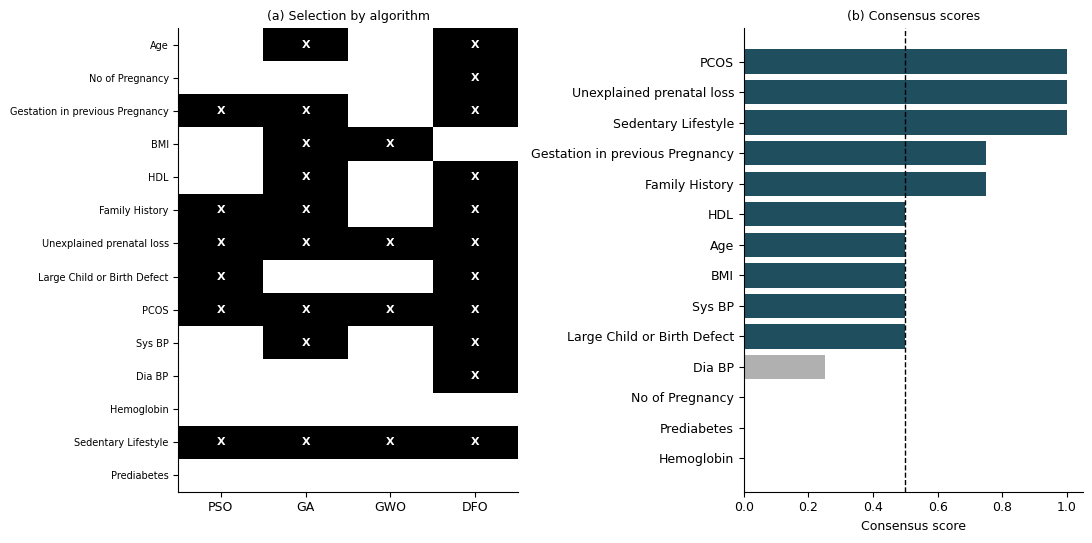

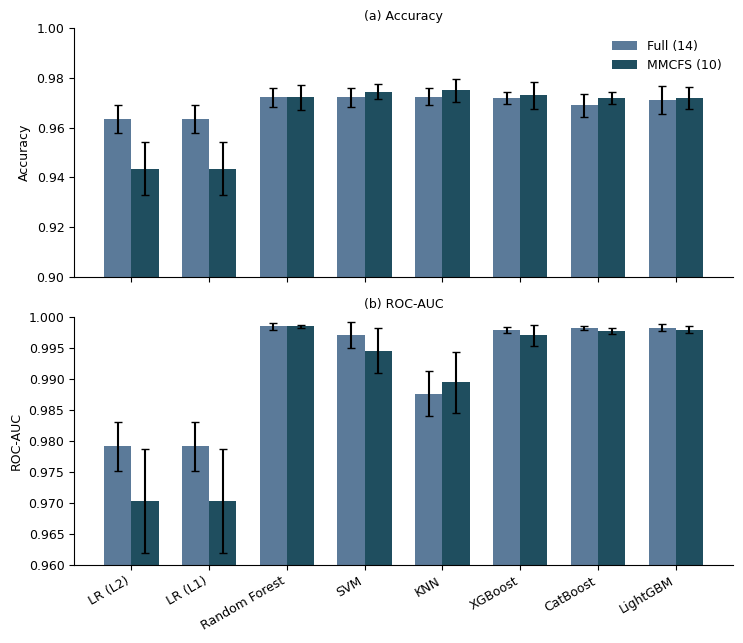

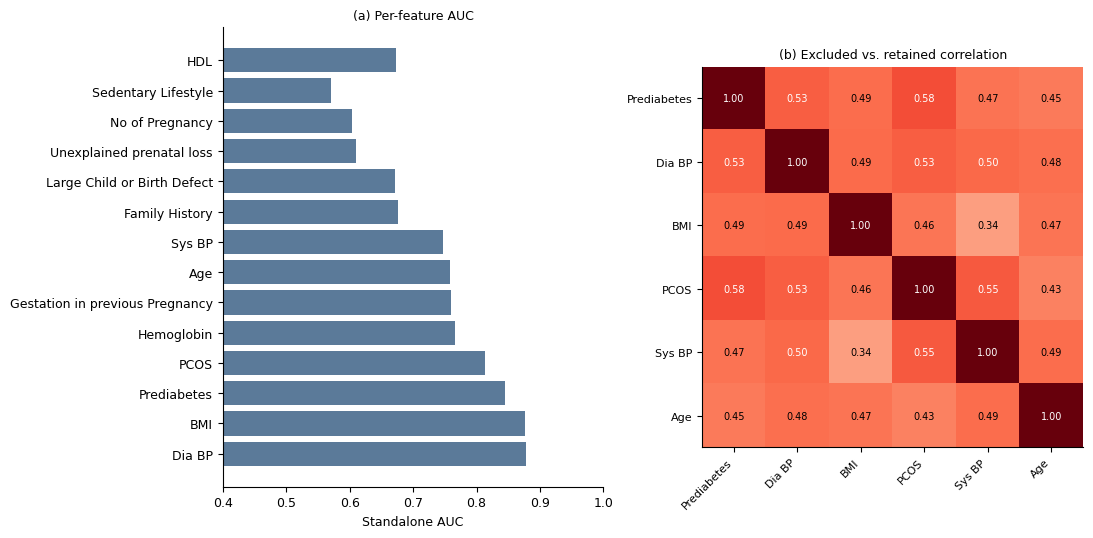

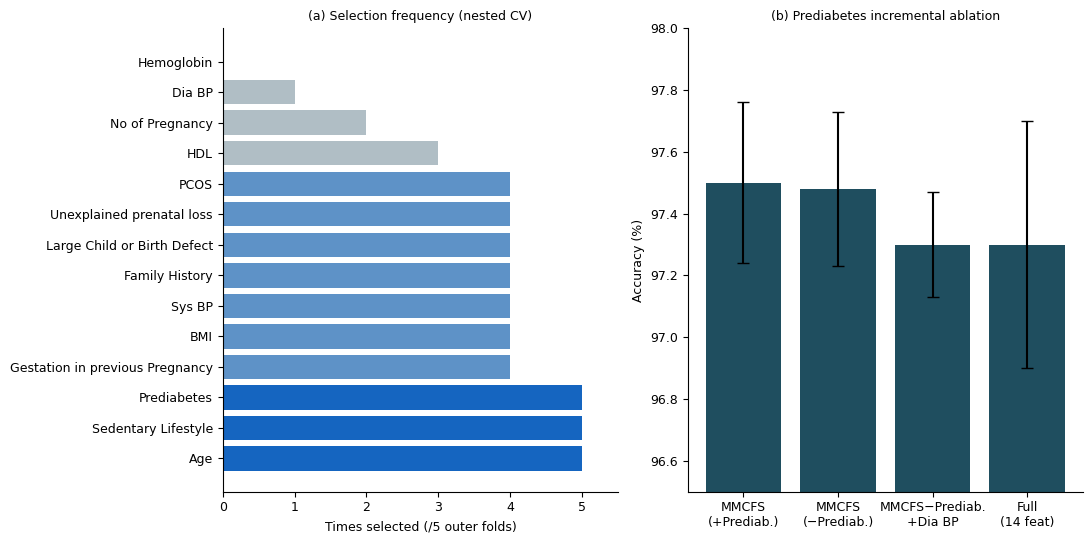

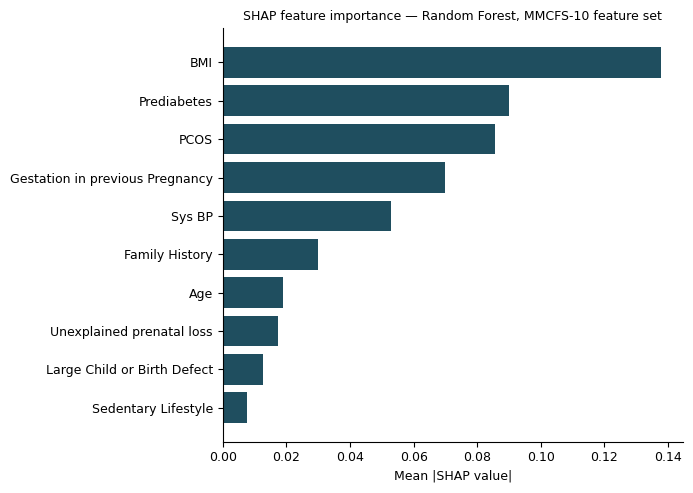

All 6 figures saved: fig2 through fig6 (Figure 1 is your architecture diagram, already made).


In [ ]:
# ============================================================
# ALL 6 PAPER FIGURES — SINGLE STANDALONE CELL
# No dependency on prior pipeline state. Uses hardcoded results
# from the completed run. Just run this cell directly.
# ============================================================
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

COLOR_FULL  = '#5B7A99'
COLOR_MMCFS = '#1F4E5F'
plt.rcParams.update({'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False})

# ------------------------------------------------------------
# FIGURE 2: Feature selection by algorithm + consensus scores
# ------------------------------------------------------------
features = ['Age','No of Pregnancy','Gestation in previous Pregnancy','BMI','HDL',
            'Family History','Unexplained prenatal loss','Large Child or Birth Defect',
            'PCOS','Sys BP','Dia BP','Hemoglobin','Sedentary Lifestyle','Prediabetes']

selection = pd.DataFrame({
    'PSO': [0,0,1,0,0,1,1,1,1,0,0,0,1,0],
    'GA':  [1,0,1,1,1,1,1,0,1,1,0,0,1,0],
    'GWO': [0,0,0,1,0,0,1,0,1,0,0,0,1,0],
    'DFO': [1,1,1,0,1,1,1,1,1,1,1,0,1,0],
}, index=features)

consensus_scores = pd.Series({
    'PCOS':1.00, 'Unexplained prenatal loss':1.00, 'Sedentary Lifestyle':1.00,
    'Family History':0.75, 'Gestation in previous Pregnancy':0.75,
    'BMI':0.50, 'Large Child or Birth Defect':0.50, 'Sys BP':0.50, 'Age':0.50, 'HDL':0.50,
    'Dia BP':0.25, 'No of Pregnancy':0.00, 'Hemoglobin':0.00, 'Prediabetes':0.00
}).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
axes[0].imshow(selection.values, cmap='Greys', aspect='auto', vmin=0, vmax=1)
axes[0].set_xticks(range(4)); axes[0].set_xticklabels(selection.columns)
axes[0].set_yticks(range(len(features))); axes[0].set_yticklabels(features, fontsize=7)
for i in range(len(features)):
    for j in range(4):
        v = selection.values[i, j]
        axes[0].text(j, i, 'X' if v else '', ha='center', va='center',
                     color='white' if v else 'black', fontsize=8, fontweight='bold')
axes[0].set_title('(a) Selection by algorithm', fontsize=9)

colors = [COLOR_MMCFS if v >= 0.5 else '#B0B0B0' for v in consensus_scores.values]
axes[1].barh(consensus_scores.index, consensus_scores.values, color=colors)
axes[1].axvline(0.5, color='black', linestyle='--', linewidth=1)
axes[1].set_xlabel('Consensus score'); axes[1].set_title('(b) Consensus scores', fontsize=9)
plt.tight_layout()
plt.savefig('fig2_selection_consensus.png', dpi=300, bbox_inches='tight')
plt.show()

# ------------------------------------------------------------
# FIGURE 3: Accuracy + ROC-AUC, Full vs MMCFS, 8 models
# ------------------------------------------------------------
models = ['LR (L2)','LR (L1)','Random Forest','SVM','KNN','XGBoost','CatBoost','LightGBM']
full_acc      = [0.9634,0.9634,0.9722,0.9722,0.9725,0.9719,0.9691,0.9711]
full_acc_std  = [0.0056,0.0056,0.0039,0.0038,0.0033,0.0023,0.0046,0.0057]
mmcfs_acc     = [0.9435,0.9435,0.9722,0.9745,0.9750,0.9730,0.9719,0.9719]
mmcfs_acc_std = [0.0106,0.0106,0.0050,0.0031,0.0045,0.0055,0.0024,0.0045]
full_auc      = [0.9791,0.9791,0.9984,0.9971,0.9876,0.9978,0.9981,0.9982]
full_auc_std  = [0.0039,0.0039,0.0005,0.0021,0.0036,0.0005,0.0003,0.0006]
mmcfs_auc     = [0.9703,0.9703,0.9984,0.9945,0.9894,0.9970,0.9977,0.9979]
mmcfs_auc_std = [0.0084,0.0084,0.0003,0.0036,0.0049,0.0017,0.0005,0.0005]

x = np.arange(len(models)); width = 0.35
fig, axes = plt.subplots(2, 1, figsize=(7.5, 6.5))
axes[0].bar(x-width/2, full_acc, width, yerr=full_acc_std, capsize=3, label='Full (14)', color=COLOR_FULL)
axes[0].bar(x+width/2, mmcfs_acc, width, yerr=mmcfs_acc_std, capsize=3, label='MMCFS (10)', color=COLOR_MMCFS)
axes[0].set_ylabel('Accuracy'); axes[0].set_ylim(0.90,1.0); axes[0].set_xticks(x); axes[0].set_xticklabels([])
axes[0].legend(frameon=False); axes[0].set_title('(a) Accuracy', fontsize=9)

axes[1].bar(x-width/2, full_auc, width, yerr=full_auc_std, capsize=3, color=COLOR_FULL)
axes[1].bar(x+width/2, mmcfs_auc, width, yerr=mmcfs_auc_std, capsize=3, color=COLOR_MMCFS)
axes[1].set_ylabel('ROC-AUC'); axes[1].set_ylim(0.96,1.0)
axes[1].set_xticks(x); axes[1].set_xticklabels(models, rotation=30, ha='right')
axes[1].set_title('(b) ROC-AUC', fontsize=9)
plt.tight_layout()
plt.savefig('fig3_acc_auc_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

# ------------------------------------------------------------
# FIGURE 4: Standalone AUC + redundancy correlation heatmap
# ------------------------------------------------------------
auc_feats = ['Dia BP','BMI','Prediabetes','PCOS','Hemoglobin','Gestation in previous Pregnancy',
             'Age','Sys BP','Family History','Large Child or Birth Defect',
             'Unexplained prenatal loss','No of Pregnancy','Sedentary Lifestyle','HDL']
auc_vals = [0.8777,0.8757,0.8454,0.8138,0.7668,0.7602,0.7586,0.7468,
            0.6769,0.6708,0.6107,0.6038,0.5705,0.6729]  # HDL direction-corrected

corr_cols = ['Prediabetes','Dia BP','BMI','PCOS','Sys BP','Age']
corr_matrix = np.array([
    [1.000,0.528,0.489,0.577,0.471,0.447],
    [0.528,1.000,0.493,0.528,0.501,0.482],
    [0.489,0.493,1.000,0.462,0.339,0.465],
    [0.577,0.528,0.462,1.000,0.545,0.426],
    [0.471,0.501,0.339,0.545,1.000,0.490],
    [0.447,0.482,0.465,0.426,0.490,1.000],
])

fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
axes[0].barh(auc_feats, auc_vals, color=COLOR_FULL)
axes[0].set_xlabel('Standalone AUC'); axes[0].set_xlim(0.4,1.0)
axes[0].set_title('(a) Per-feature AUC', fontsize=9)

im = axes[1].imshow(corr_matrix, cmap='Reds', vmin=0, vmax=1)
axes[1].set_xticks(range(6)); axes[1].set_xticklabels(corr_cols, rotation=45, ha='right', fontsize=8)
axes[1].set_yticks(range(6)); axes[1].set_yticklabels(corr_cols, fontsize=8)
for i in range(6):
    for j in range(6):
        axes[1].text(j, i, f"{corr_matrix[i,j]:.2f}", ha='center', va='center', fontsize=7,
                     color='white' if corr_matrix[i,j] > 0.5 else 'black')
axes[1].set_title('(b) Excluded vs. retained correlation', fontsize=9)
plt.tight_layout()
plt.savefig('fig4_auc_redundancy.png', dpi=300, bbox_inches='tight')
plt.show()

# ------------------------------------------------------------
# FIGURE 5: Selection frequency + Prediabetes ablation
# ------------------------------------------------------------
freq_feats = ['Age','Sedentary Lifestyle','Prediabetes','Gestation in previous Pregnancy',
              'BMI','Sys BP','Family History','Large Child or Birth Defect',
              'Unexplained prenatal loss','PCOS','HDL','No of Pregnancy','Dia BP','Hemoglobin']
freq_vals = [5,5,5,4,4,4,4,4,4,4,3,2,1,0]
freq_colors = ['#1565C0' if v==5 else '#5E92C7' if v>=4 else '#B0BEC5' for v in freq_vals]

fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))
axes[0].barh(freq_feats, freq_vals, color=freq_colors)
axes[0].set_xlabel('Times selected (/5 outer folds)'); axes[0].set_xlim(0, 5.5)
axes[0].set_title('(a) Selection frequency (nested CV)', fontsize=9)

variants = ['MMCFS\n(+Prediab.)','MMCFS\n(−Prediab.)','MMCFS−Prediab.\n+Dia BP','Full\n(14 feat)']
ablation_acc = [97.50, 97.48, 97.30, 97.30]
ablation_err = [0.26, 0.25, 0.17, 0.40]
axes[1].bar(variants, ablation_acc, yerr=ablation_err, capsize=4, color=COLOR_MMCFS)
axes[1].set_ylabel('Accuracy (%)'); axes[1].set_ylim(96.5, 98)
axes[1].set_title('(b) Prediabetes incremental ablation', fontsize=9)
plt.tight_layout()
plt.savefig('fig5_frequency_ablation.png', dpi=300, bbox_inches='tight')
plt.show()

# ------------------------------------------------------------
# FIGURE 6: SHAP — mean |SHAP| bar chart (see note above)
# ------------------------------------------------------------
shap_feats = ['BMI','Prediabetes','PCOS','Gestation in previous Pregnancy','Sys BP',
              'Family History','Age','Unexplained prenatal loss',
              'Large Child or Birth Defect','Sedentary Lifestyle']
shap_vals = [0.1378,0.0899,0.0857,0.0698,0.0528,0.0301,0.0189,0.0174,0.0128,0.0076]

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(shap_feats[::-1], shap_vals[::-1], color=COLOR_MMCFS)
ax.set_xlabel('Mean |SHAP value|')
ax.set_title('SHAP feature importance — Random Forest, MMCFS-10 feature set', fontsize=9)
plt.tight_layout()
plt.savefig('fig6_shap_importance.png', dpi=300, bbox_inches='tight')
plt.show()

print("All 6 figures saved: fig2 through fig6 (Figure 1 is your architecture diagram, already made).")